In [1]:
import astropy.table as at
import numpy as np

In [2]:
from astropy.table import Table

t = Table.read('astraAllStarASPCAP-0.8.fits.gz', format='fits', hdu=2)  

Using STARFLAG column: flag_bad
Stars passing STARFLAG==0: 1935115
Using photogeo fractional distance cut: 0.5*(r_hi-r_lo)/r_med < 0.20
Final selected sample size: 816745
Low-α count: 656931
High-α count: 159814


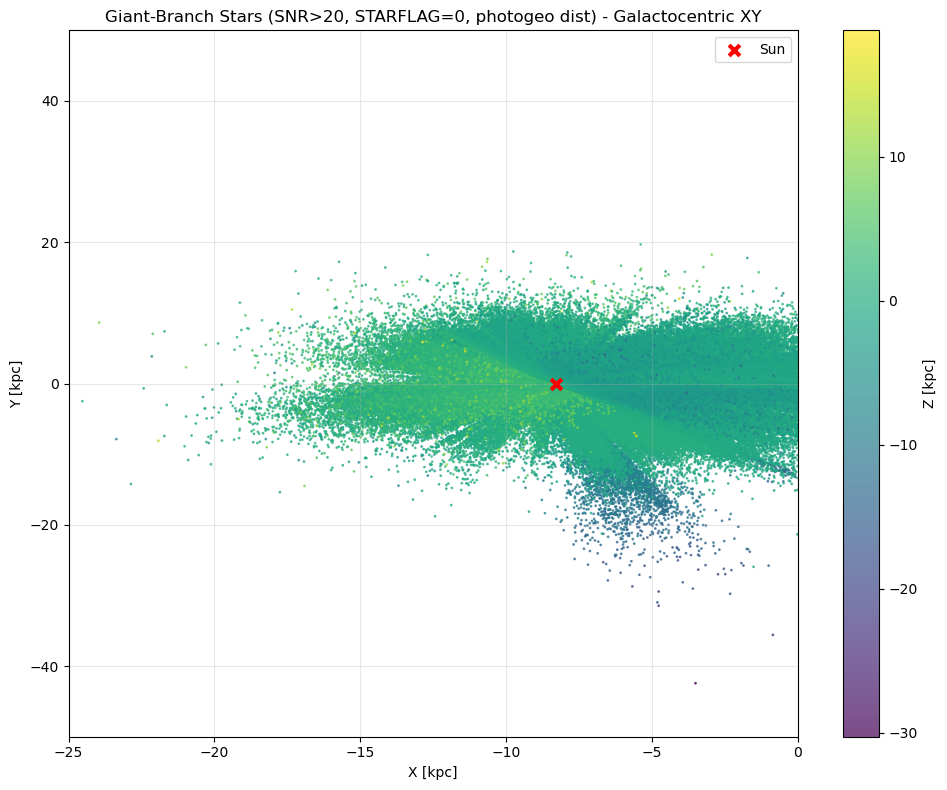

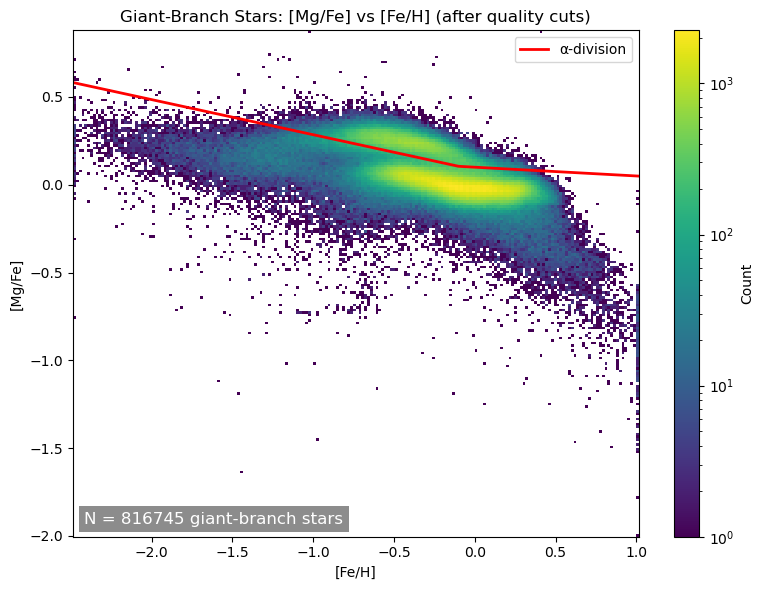

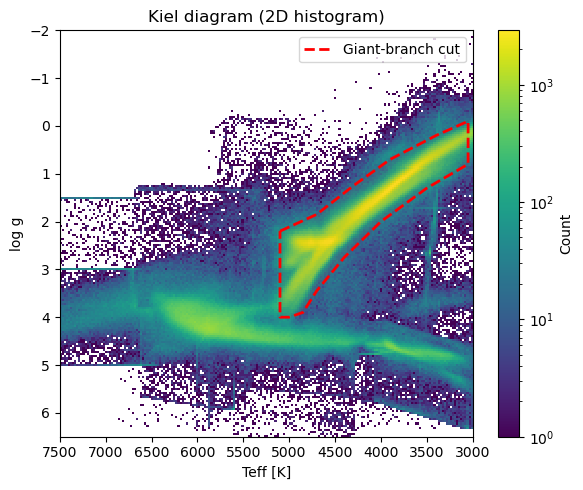

In [12]:
# ============================================================
# Full end-to-end pipeline (UPDATED):
#   - Use MAIN GIANT BRANCH polygon cut in Teff–logg (Kiel)
#   - Keep the same quality cuts (incl. optional frac dist err < 20%)
#   - Make the same 3 plots as your code:
#       1) XY colored by Z
#       2) [Mg/Fe] vs [Fe/H] + alpha division
#       3) Kiel diagram (2D hist) + polygon outline
#   - Kiel plot: invert x and invert y
# ============================================================

from astropy.table import Table
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# -----------------------------
# 0) Load table
# -----------------------------
t = Table.read('astraAllStarASPCAP-0.8.fits.gz', format='fits', hdu=2)

# -----------------------------
# 1) Pull needed columns as arrays
# -----------------------------
teff = np.asarray(t['teff'], float)
logg = np.asarray(t['logg'], float)
feh  = np.asarray(t['fe_h'], float)
mgh  = np.asarray(t['mg_h'], float)
snr  = np.asarray(t['snr'], float)

ra   = np.asarray(t['ra'], float)
dec  = np.asarray(t['dec'], float)
pmra = np.asarray(t['pmra'], float)
pmde = np.asarray(t['pmde'], float)
vrad = np.asarray(t['v_rad'], float)

# Photogeometric distance (you said you want to use this)
rmed = np.asarray(t['r_med_photogeo'], float)  # commonly in pc

# Optional photogeo lo/hi bounds (may not exist)
has_lohi = ('r_lo_photogeo' in t.colnames) and ('r_hi_photogeo' in t.colnames)
if has_lohi:
    rlo = np.asarray(t['r_lo_photogeo'], float)
    rhi = np.asarray(t['r_hi_photogeo'], float)
else:
    rlo = rhi = None

# -----------------------------
# 2) Find STARFLAG column & build STARFLAG==0 mask
# -----------------------------
possible_starflag_cols = ['flag_bad']
starflag_col = next((c for c in possible_starflag_cols if c in t.colnames), None)
if starflag_col is None:
    raise KeyError("No STARFLAG column found. Check t.colnames for the correct name (e.g., 'STARFLAG' or 'starflag').")

starflag = np.asarray(t[starflag_col])
starflag_mask = (starflag == 0)

print(f"Using STARFLAG column: {starflag_col}")
print(f"Stars passing STARFLAG==0: {int(np.sum(starflag_mask))}")

# -----------------------------
# 3) Basic finiteness masks
# -----------------------------
finite_basic = np.isfinite(teff) & np.isfinite(logg)
finite_chem  = finite_basic & np.isfinite(feh) & np.isfinite(mgh) & np.isfinite(snr)

# ----------------------------------------
# Remove cluster members (GCs, OCs, dSphs)
# ----------------------------------------
member_flags = np.asarray(t['sdss4_apogee_member_flags'], dtype=np.int64)
no_cluster = (member_flags == 0)

# -----------------------------
# 4) MAIN GIANT BRANCH selection (polygon; straight-line boundaries)
#    This is meant to resemble your pink outline.
#    Tweak vertices if you want it tighter/looser.
# -----------------------------
gb_vertices = np.array([
    # upper boundary (left -> right)
    [5100, 2.20],
    [4700, 1.85],
    [4300, 1.25],
    [3900, 0.70],
    [3400, 0.20],
    [3050, -0.10],

    # lower boundary (right -> left back toward the "wall")
    [3050, 0.80],
    [3500, 1.30],
    [4000, 2.00],
    [4400, 2.75],
    [4700, 3.45],
    [4850, 3.90],
    [5000, 4.00],
    [5100, 4.00],
])

gb_path = Path(gb_vertices, closed=True)
giant_branch_mask = gb_path.contains_points(np.vstack([teff, logg]).T)

# Optional guard rails (keeps it sane)
giant_branch_mask &= (teff >= 3000) & (teff <= 7500) & (logg > -2) & (logg < 6.5)

# -----------------------------
# 5) QUALITY CUTS to apply BEFORE slicing the table
# -----------------------------

# QUALITY CUT: SNR > 20
snr_mask = (snr > 20)

# QUALITY CUT: photogeometric distance present and positive
dist_mask = np.isfinite(rmed) & (rmed > 0)

# OPTIONAL QUALITY CUT: photogeo fractional distance uncertainty
frac_cut = 0.20
if has_lohi:
    frac_dist_err = 0.5 * (rhi - rlo) / rmed
    dist_mask = dist_mask & np.isfinite(frac_dist_err) & (frac_dist_err < frac_cut)
    print(f"Using photogeo fractional distance cut: 0.5*(r_hi-r_lo)/r_med < {frac_cut:.2f}")
else:
    print("No r_lo_photogeo/r_hi_photogeo columns found — skipping fractional distance-error cut.")

# QUALITY CUT: finite 6D inputs needed for Galactocentric transform
kin_mask = (
    np.isfinite(ra) & np.isfinite(dec) &
    np.isfinite(pmra) & np.isfinite(pmde) &
    np.isfinite(vrad)
)

# -----------------------------
# 6) Master mask = everything combined
# -----------------------------
master_mask = (
    finite_chem &         # finite Teff/logg/FeH/MgH/SNR
    giant_branch_mask &   # MAIN GIANT BRANCH polygon
    snr_mask &            # QUALITY: SNR > 20
    starflag_mask &       # QUALITY: STARFLAG == 0
    no_cluster &          # remove cluster members
    dist_mask &           # valid photogeo distance (+ optional frac_err cut)
    kin_mask              # finite 6D kinematic inputs
)

t_sel = t[master_mask]
print("Final selected sample size:", len(t_sel))

# -----------------------------
# 7) Build SkyCoord using photogeo distance
#    ASSUMPTION: r_med_photogeo is in pc (most common).
# -----------------------------
dist = Distance(np.asarray(t_sel['r_med_photogeo'], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_sel['ra'], float) * u.deg,
    dec=np.asarray(t_sel['dec'], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_sel['pmra'], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_sel['pmde'], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_sel['v_rad'], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)
galcen = c.transform_to(galcen_frame)

x = galcen.x.to_value(u.kpc)
y = galcen.y.to_value(u.kpc)
z = galcen.z.to_value(u.kpc)
vx = galcen.v_x.to_value(u.km/u.s)
vy = galcen.v_y.to_value(u.km/u.s)
vz = galcen.v_z.to_value(u.km/u.s)

# -----------------------------
# 8) Chemistry: [Mg/Fe] and low-α / high-α separation
# -----------------------------
fe   = np.asarray(t_sel['fe_h'], float)
mgfe = np.asarray(t_sel['mg_h'], float) - fe

finite_alpha = np.isfinite(fe) & np.isfinite(mgfe)
fe, mgfe = fe[finite_alpha], mgfe[finite_alpha]

# (keep coords aligned with chemistry finiteness for potential later use)
x_a, y_a, z_a = x[finite_alpha], y[finite_alpha], z[finite_alpha]

# Piecewise alpha division (one source of truth)
fe_break = -0.1
m1, b1 = -0.05, 0.10
m2 = -0.20
b2 = (m1 * fe_break + b1) - m2 * fe_break  # continuity

def mgfe_dividing_line(feh_vals):
    feh_vals = np.asarray(feh_vals, float)
    return np.where(feh_vals >= fe_break, m1*feh_vals + b1, m2*feh_vals + b2)

mgfe_div = mgfe_dividing_line(fe)
low_alpha  = mgfe < mgfe_div
high_alpha = ~low_alpha

print("Low-α count:", int(np.sum(low_alpha)))
print("High-α count:", int(np.sum(high_alpha)))

# -----------------------------
# 9) Plot 1: XY colored by Z  (same style as your code)
# -----------------------------
plt.figure(figsize=(10, 8))
plt.scatter(x, y, c=z, s=1, alpha=0.7, cmap='viridis')
plt.colorbar(label='Z [kpc]')
plt.scatter(-8.275, 0, marker='x', s=60, c='red', linewidths=3, label='Sun', zorder=5)

plt.xlabel('X [kpc]')
plt.ylabel('Y [kpc]')
plt.title('Giant-Branch Stars (SNR>20, STARFLAG=0, photogeo dist) - Galactocentric XY')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(-25, 0)
plt.ylim(-50, 50)
plt.tight_layout()
plt.show()

# -----------------------------
# 10) Plot 2: Mg/Fe vs Fe/H + α division (same style as your code)
# -----------------------------
plt.figure(figsize=(8, 6))
plt.hist2d(fe, mgfe, bins=200, norm=LogNorm(), cmap='viridis')
plt.colorbar(label='Count')

fe_grid = np.linspace(np.nanmin(fe), np.nanmax(fe), 400)
plt.plot(fe_grid, mgfe_dividing_line(fe_grid), color='red', lw=2, label='α-division')

plt.text(
    0.02, 0.02,
    f"N = {len(fe)} giant-branch stars",
    transform=plt.gca().transAxes,
    fontsize=12,
    va='bottom',
    color='white',
    bbox=dict(facecolor='grey', alpha=0.9, edgecolor='none', pad=4)
)

plt.xlabel('[Fe/H]')
plt.ylabel('[Mg/Fe]')
plt.title('Giant-Branch Stars: [Mg/Fe] vs [Fe/H] (after quality cuts)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# -----------------------------
# 11) Plot 3: Kiel diagram (full sample) + polygon overlay
#     - invert x axis (hot left)
#     - invert y axis (high logg at bottom)
# -----------------------------
x_all = teff[finite_basic]
y_all = logg[finite_basic]

plt.figure(figsize=(6, 5))
plt.hist2d(x_all, y_all, bins=200, range=[(3000, 7500), (-2, 6.5)], norm=LogNorm(), cmap='viridis')
plt.gca().invert_xaxis()
plt.gca().invert_yaxis()
plt.colorbar(label='Count')

plt.xlabel('Teff [K]')
plt.ylabel('log g')
plt.xlim(7500, 3000)
plt.title('Kiel diagram (2D histogram)')

# polygon outline
gb_closed = np.vstack([gb_vertices, gb_vertices[0]])
plt.plot(gb_closed[:, 0], gb_closed[:, 1], 'r--', lw=2, label='Giant-branch cut')

# optional: light fill so you can see what’s included
plt.fill(gb_closed[:, 0], gb_closed[:, 1], color='red', alpha=0.06)

plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig("kiel.png", dpi=300, bbox_inches="tight")
plt.show()


Finite points: 798535
Inside polygon: 276750
Polygon-selected sample: 276750


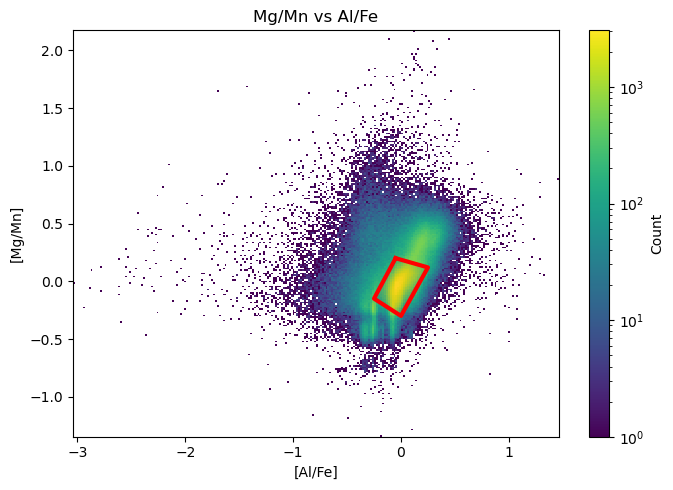

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.path import Path

alfe = np.asarray(t_sel['al_h'], float) - np.asarray(t_sel['fe_h'], float)
mgmn = np.asarray(t_sel['mg_h'], float) - np.asarray(t_sel['mn_h'], float)

finite = np.isfinite(alfe) & np.isfinite(mgmn)
x = alfe[finite]
y = mgmn[finite]

# --- UPDATED quadrilateral ---
poly_vertices = np.array([
    [-0.05, 0.2],  # upper-left
    [ 0.25,  0.12],  # upper-right
    [ 0.0, -0.3],  # lower-right
    [-0.25, -0.15],  # lower-left
])

poly_path = Path(poly_vertices, closed=True)
pts = np.vstack([x, y]).T
inside = poly_path.contains_points(pts)

poly_mask_full = np.zeros(len(t_sel), dtype=bool)
poly_mask_full[np.where(finite)[0]] = inside
t_poly = t_sel[poly_mask_full]

print("Finite points:", len(pts))
print("Inside polygon:", int(np.sum(inside)))
print("Polygon-selected sample:", len(t_poly))

plt.figure(figsize=(7,5))
plt.hist2d(x, y, bins=250, norm=LogNorm(), cmap="viridis")
plt.colorbar(label="Count")
plt.xlabel("[Al/Fe]")
plt.ylabel("[Mg/Mn]")
plt.title("Mg/Mn vs Al/Fe")

closed = np.vstack([poly_vertices, poly_vertices[0]])
plt.plot(closed[:,0], closed[:,1], color="red", lw=3)
plt.fill(closed[:,0], closed[:,1], color="red", alpha=0.08)

plt.tight_layout()
plt.show()


In [40]:
import numpy as np
import matplotlib.pyplot as plt

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance
from matplotlib.colors import LogNorm

# ------------------------------------------------------------
# Build SkyCoord for your final sample (e.g., t_triangle)
# ------------------------------------------------------------
dist = Distance(np.asarray(t_poly['r_med_photogeo'], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_poly['ra'], float) * u.deg,
    dec=np.asarray(t_poly['dec'], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_poly['pmra'], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_poly['pmde'], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_poly
        ['v_rad'], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

gc = c.transform_to(galcen_frame)

# ------------------------------------------------------------
# Pull Cartesian positions/velocities (km/s, kpc)
# ------------------------------------------------------------
x  = gc.x.to_value(u.kpc)
y  = gc.y.to_value(u.kpc)
z  = gc.z.to_value(u.kpc)

vx = gc.v_x.to_value(u.km/u.s)
vy = gc.v_y.to_value(u.km/u.s)
vz = gc.v_z.to_value(u.km/u.s)

R = np.sqrt(x**2 + y**2)

# avoid divide-by-zero if any stars are at R~0 (unlikely)
goodR = np.isfinite(R) & (R > 1e-6)
x, y, z, vx, vy, vz, R = x[goodR], y[goodR], z[goodR], vx[goodR], vy[goodR], vz[goodR], R[goodR]

# ------------------------------------------------------------
# Cylindrical velocities from Cartesian
# vR  = (x vx + y vy)/R
# vphi = (-x vy + y vx)/R   (right-handed, rotation direction)
# vz  = vz
# ------------------------------------------------------------
vR   = (x*vx + y*vy) / R
vphi = (-x*vy + y*vx) / R
vz   = vz

# ------------------------------------------------------------
# Toomre variables relative to (your) Sun rotation choice
# Using your galcen_v_sun=[8,254,8] -> take vphi_sun ~ 254 km/s
# ------------------------------------------------------------
vphi_sun = 254.0

U_lsr = -vR
V_lsr = vphi - vphi_sun
W_lsr = vz

T = np.sqrt(U_lsr**2 + W_lsr**2)

Toomre diagram sample size: 276750


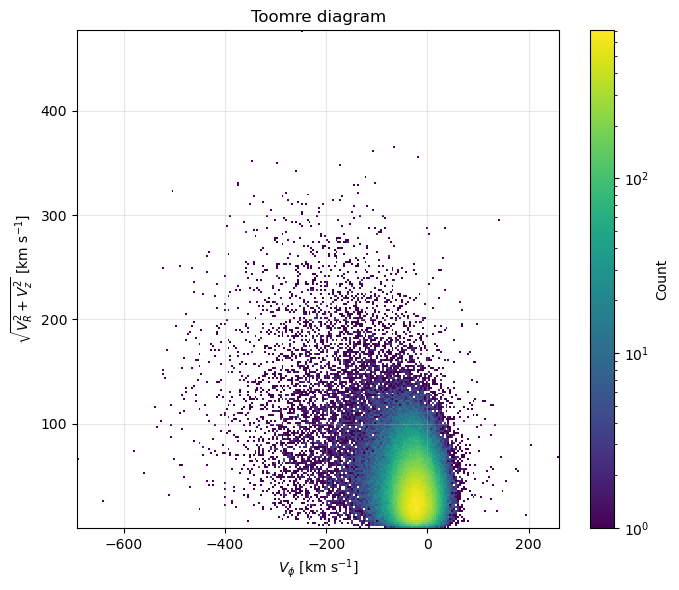

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# V_lsr and T were computed from t_poly, then filtered by goodR already
# just do a final finiteness mask:
finite_kin = np.isfinite(V_lsr) & np.isfinite(T)
Vphi_cut = V_lsr[finite_kin]
T_cut    = T[finite_kin]

print("Toomre diagram sample size:", len(Vphi_cut))

plt.figure(figsize=(7, 6))
plt.hist2d(Vphi_cut, T_cut, bins=250, norm=LogNorm(), cmap="viridis")
plt.colorbar(label="Count")

plt.xlabel(r'$V_\phi$ [km s$^{-1}$]')
plt.ylabel(r'$\sqrt{V_R^2 + V_z^2}$ [km s$^{-1}$]')
plt.title("Toomre diagram")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

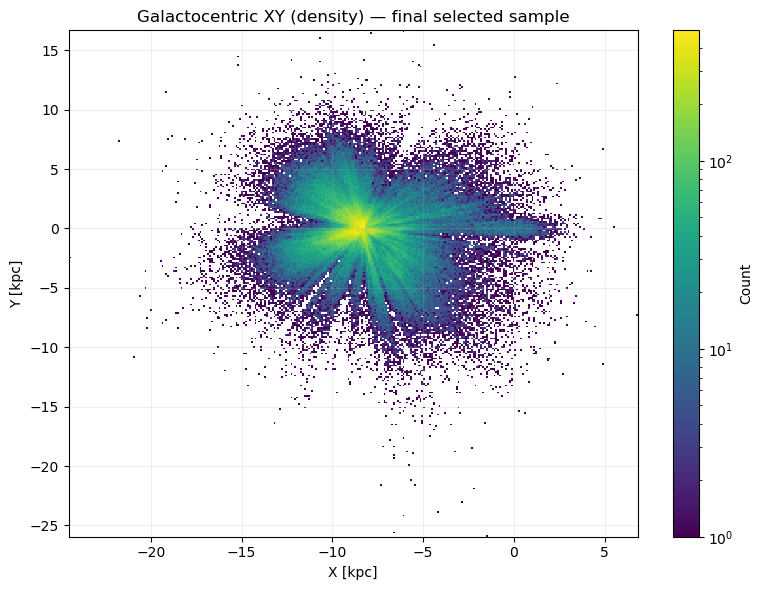

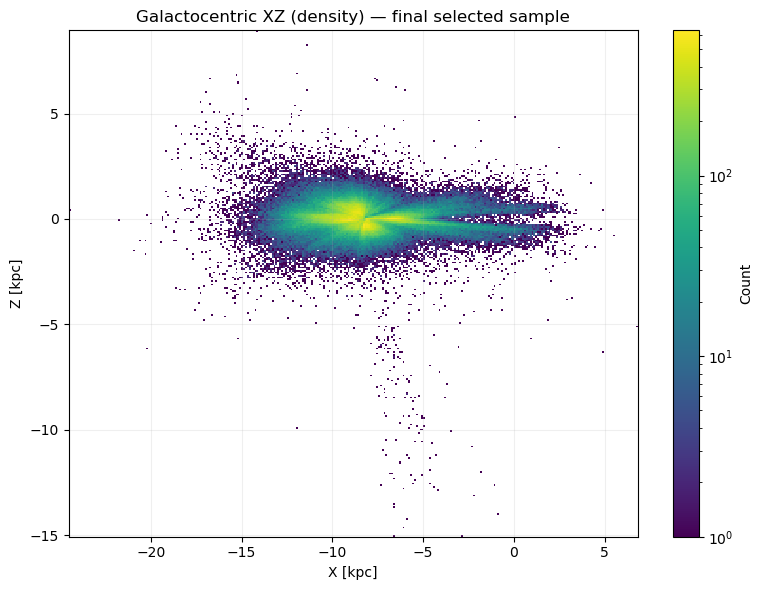

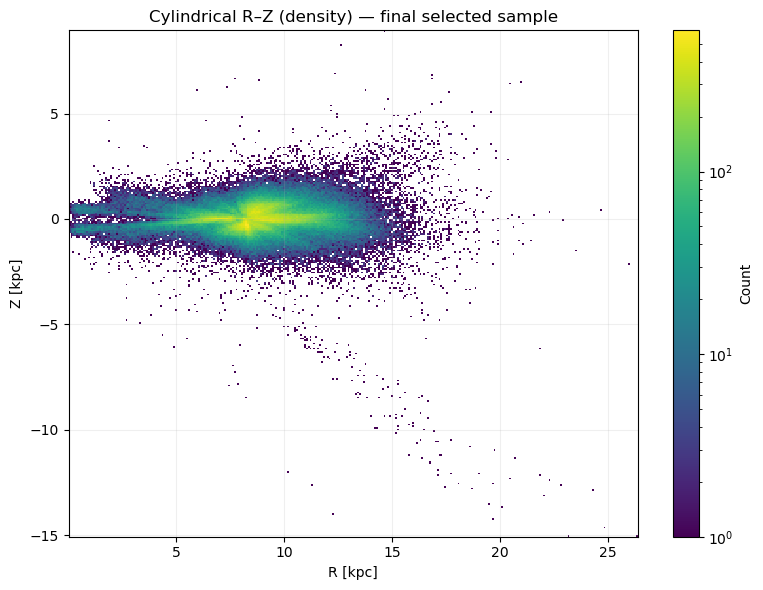

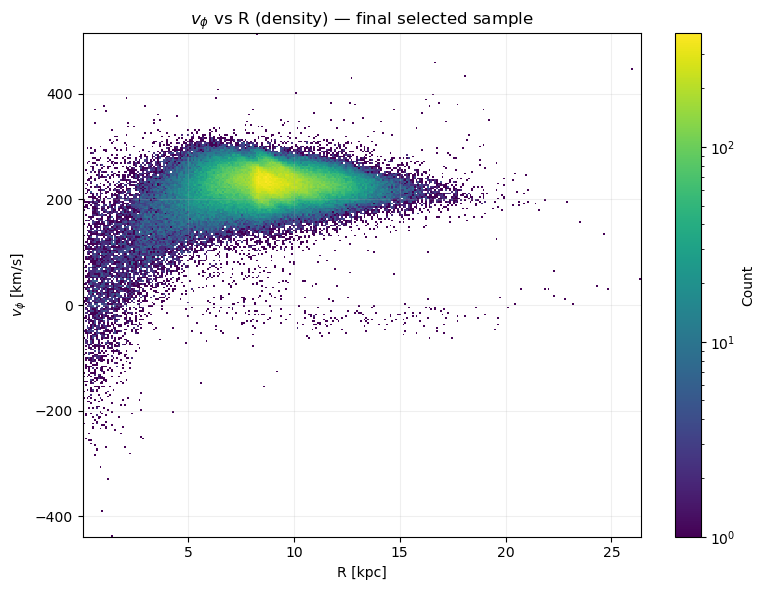

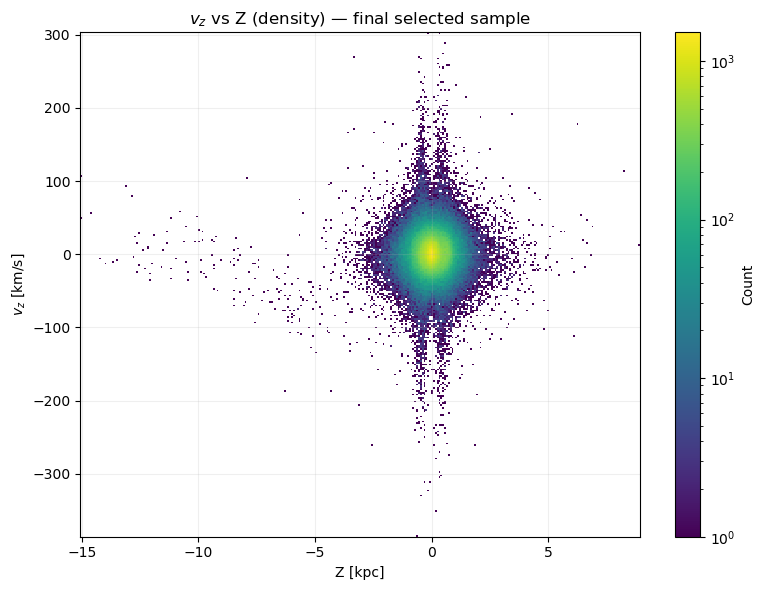

N stars in phase-space maps: 276750
R range [kpc]: 0.02449931897398819 to 26.37666733590186
Z range [kpc]: -15.070206195585865 to 8.945595370307027
Median vphi [km/s]: 228.85076335146908
Median |vz| [km/s]: 12.673260952586428


In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ------------------------------------------------------------
# Choose your FINAL selected table
# (giant-branch cut + chemical polygon cut)
# ------------------------------------------------------------
t_final = t_poly   # <-- this is "all the selected stars" now

# ------------------------------------------------------------
# 1) Build SkyCoord and transform to Galactocentric
# ------------------------------------------------------------
dist = Distance(np.asarray(t_final['r_med_photogeo'], float) * u.pc)  # change to u.kpc if needed

c = SkyCoord(
    ra=np.asarray(t_final['ra'], float) * u.deg,
    dec=np.asarray(t_final['dec'], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_final['pmra'], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_final['pmde'], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_final['v_rad'], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

gc = c.transform_to(galcen_frame)

# Cartesian positions/velocities
X  = gc.x.to_value(u.kpc)
Y  = gc.y.to_value(u.kpc)
Z  = gc.z.to_value(u.kpc)
VX = gc.v_x.to_value(u.km/u.s)
VY = gc.v_y.to_value(u.km/u.s)
VZ = gc.v_z.to_value(u.km/u.s)

# ------------------------------------------------------------
# 2) Cylindrical coordinates and velocities (computed from Cartesian)
# ------------------------------------------------------------
R   = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y, X)  # radians (not used below, but kept for completeness)

# Avoid divide-by-zero and NaNs
good = np.isfinite(R) & (R > 1e-6) & np.isfinite(X) & np.isfinite(Y) & np.isfinite(Z) & np.isfinite(VX) & np.isfinite(VY) & np.isfinite(VZ)
X, Y, Z, VX, VY, VZ, R, phi = X[good], Y[good], Z[good], VX[good], VY[good], VZ[good], R[good], phi[good]

# Cylindrical velocities
vR   = (X*VX + Y*VY) / R
vphi = (-X*VY + Y*VX) / R
vz   = VZ

# ------------------------------------------------------------
# 3) Plots: phase-space views (2D projections + velocity maps)
# ------------------------------------------------------------

# --- A) XY density ---
plt.figure(figsize=(8,6))
plt.hist2d(X, Y, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Galactocentric XY (density) — final selected sample")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# --- B) XZ density ---
plt.figure(figsize=(8,6))
plt.hist2d(X, Z, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("X [kpc]")
plt.ylabel("Z [kpc]")
plt.title("Galactocentric XZ (density) — final selected sample")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# --- C) R–Z density ---
plt.figure(figsize=(8,6))
plt.hist2d(R, Z, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("R [kpc]")
plt.ylabel("Z [kpc]")
plt.title("Cylindrical R–Z (density) — final selected sample")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# --- D) vphi vs R ---
plt.figure(figsize=(8,6))
plt.hist2d(R, vphi, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("R [kpc]")
plt.ylabel(r"$v_\phi$ [km/s]")
plt.title(r"$v_\phi$ vs R (density) — final selected sample")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# --- E) vz vs Z ---
plt.figure(figsize=(8,6))
plt.hist2d(Z, vz, bins=300, norm=LogNorm())
plt.colorbar(label="Count")
plt.xlabel("Z [kpc]")
plt.ylabel(r"$v_z$ [km/s]")
plt.title(r"$v_z$ vs Z (density) — final selected sample")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("N stars in phase-space maps:", len(X))
print("R range [kpc]:", np.nanmin(R), "to", np.nanmax(R))
print("Z range [kpc]:", np.nanmin(Z), "to", np.nanmax(Z))
print("Median vphi [km/s]:", np.nanmedian(vphi))
print("Median |vz| [km/s]:", np.nanmedian(np.abs(vz)))

Stopping: reached 2 consecutive annuli with N < 200 at R~[16.5,17.0)
Plotted 32 annuli (dR=0.5) until N dropped below 200.


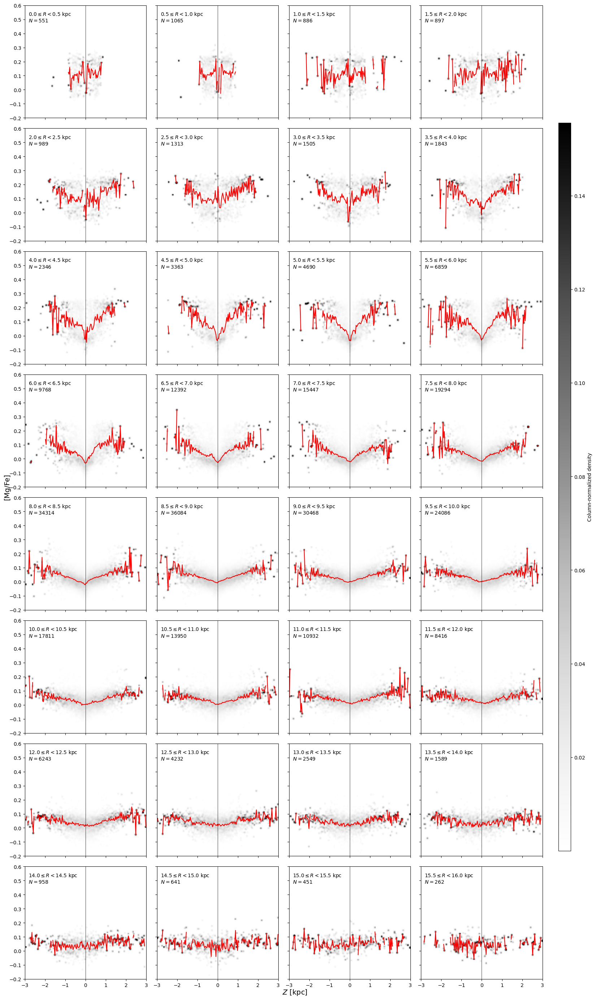

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

# ============================================================
# Use your NEW final sample
# ============================================================
t_final = t_poly   # <-- new cuts (giant-branch + chemical polygon)

# -----------------------------
# Build the arrays needed for the annuli plot
# (If you already have R_all, Z_all, mgfe_all for t_final, skip this block)
# -----------------------------
X = np.asarray(gc.x.to_value(u.kpc)) if False else None  # placeholder (ignore)

# If you already computed X,Y,Z for t_final in a previous cell, use them here.
# Otherwise, compute them from scratch like you did earlier (recommended).
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

dist = Distance(np.asarray(t_final['r_med_photogeo'], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_final['ra'], float) * u.deg,
    dec=np.asarray(t_final['dec'], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_final['pmra'], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_final['pmde'], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_final['v_rad'], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)
gc = c.transform_to(galcen_frame)

X_all = gc.x.to_value(u.kpc)
Y_all = gc.y.to_value(u.kpc)
Z_all = gc.z.to_value(u.kpc)

R_all = np.sqrt(X_all**2 + Y_all**2)

mgfe_all = (np.asarray(t_final['mg_h'], float) - np.asarray(t_final['fe_h'], float))

# Basic finiteness
finite_all = np.isfinite(R_all) & np.isfinite(Z_all) & np.isfinite(mgfe_all)
R_all = R_all[finite_all]
Z_all = Z_all[finite_all]
mgfe_all = mgfe_all[finite_all]

# ============================================================
# Multi-panel annuli grid (STOP when N < minN)
# ============================================================

# -----------------------------
# Controls
# -----------------------------
dR = 0.5
minN = 200

# stop rule: require this many consecutive low-N annuli before stopping
# (prevents stopping early due to a single dip)
stop_after_k_consecutive_lowN = 2

cmap_name = "Greys"

z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

smooth_sigma = (1.0, 1.0)
vmin_pct, vmax_pct = 2.0, 99.7

# -----------------------------
# Build annuli OUTWARD and STOP at low-N
# -----------------------------
Rmin_data = np.nanmin(R_all)
Rmax_data = np.nanmax(R_all)

Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR

annuli = []
imgs = []
mean_trends = []
Ns = []

lowN_streak = 0

for Rmin in np.arange(Rstart, Rstop, dR):
    Rmax = Rmin + dR
    m = (R_all >= Rmin) & (R_all < Rmax)
    N = int(np.sum(m))

    if N < minN:
        lowN_streak += 1
        if lowN_streak >= stop_after_k_consecutive_lowN:
            print(f"Stopping: reached {lowN_streak} consecutive annuli with N < {minN} at R~[{Rmin:.1f},{Rmax:.1f})")
            break
        else:
            # skip this annulus but keep going (in case it's a one-off dip)
            continue
    else:
        lowN_streak = 0  # reset streak

    Z = Z_all[m]
    mgfe = mgfe_all[m]

    finite = np.isfinite(Z) & np.isfinite(mgfe)
    Z = Z[finite]
    mgfe = mgfe[finite]
    N = int(len(Z))
    if N < minN:
        continue

    # Column-normalized histogram P(Mg/Fe | Z)
    H, _, _ = np.histogram2d(Z, mgfe, bins=[z_edges, mgfe_edges])
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm  = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))

    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T

    # Mean Mg/Fe trend in each Z bin
    trend = np.full_like(z_centers, np.nan, dtype=float)
    for i in range(len(z_edges) - 1):
        mm = (Z >= z_edges[i]) & (Z < z_edges[i+1])
        if np.any(mm):
            trend[i] = np.nanmean(mgfe[mm])

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trend)
    Ns.append(N)

print(f"Plotted {len(annuli)} annuli (dR={dR}) until N dropped below {minN}.")

# -----------------------------
# Shared color scale across panels
# -----------------------------
if len(imgs) > 0:
    vals = np.concatenate([img[(img > 0) & np.isfinite(img)] for img in imgs])
    if len(vals) > 0:
        vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
    else:
        vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = 0.0, 1.0

# -----------------------------
# Grid layout
# -----------------------------
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

# -----------------------------
# Plot panels
# -----------------------------
pcm = None
for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trend = mean_trends[i]
    N = Ns[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    ax.plot(z_centers, trend, color="red", lw=1.5)
    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc" + "\n" + rf"$N={N}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)

fig.supxlabel(r"$Z$ [kpc]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density")

plt.show()


Using annuli from last plot: 32 annuli
Annuli range: (np.float64(0.0), np.float64(0.5)) to (np.float64(15.5), np.float64(16.0))
N stars in XY context: 276585


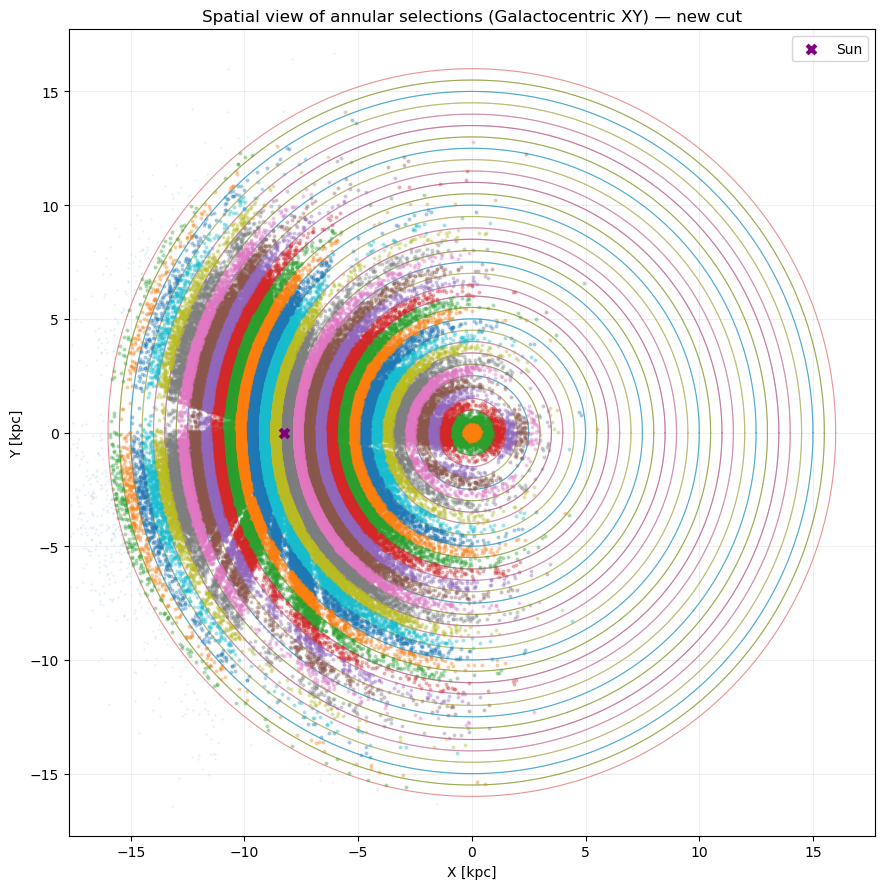

In [63]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# -----------------------------
# Final sample (NEW CUT)
# -----------------------------
t_final = t_poly  # new cut

# -----------------------------
# Reuse annuli from your last plot
# -----------------------------
if 'annuli' not in globals() or len(annuli) == 0:
    raise ValueError("I can't find `annuli` from the previous plot. Run the annuli-grid cell first (the one that builds `annuli`).")

print("Using annuli from last plot:", len(annuli), "annuli")
print("Annuli range:", annuli[0], "to", annuli[-1])

# -----------------------------
# Build Galactocentric coords
# -----------------------------
dist = Distance(np.asarray(t_final['r_med_photogeo'], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_final['ra'], float) * u.deg,
    dec=np.asarray(t_final['dec'], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_final['pmra'], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_final['pmde'], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_final['v_rad'], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)
gc = c.transform_to(galcen_frame)

X = gc.x.to_value(u.kpc)
Y = gc.y.to_value(u.kpc)
Z = gc.z.to_value(u.kpc)
R = np.sqrt(X**2 + Y**2)
absZ = np.abs(Z)

# -----------------------------
# Base mask (same idea as your code)
# -----------------------------
Zmax = 5.0
base_mask = np.isfinite(X) & np.isfinite(Y) & np.isfinite(R) & np.isfinite(absZ) & (absZ < Zmax)

Xb, Yb, Rb = X[base_mask], Y[base_mask], R[base_mask]
print("N stars in XY context:", len(Xb))

# -----------------------------
# Plot: XY with annuli boundaries + highlighted stars
# -----------------------------
plt.figure(figsize=(9, 9))

# context cloud
plt.scatter(Xb, Yb, s=1, alpha=0.06, zorder=1)

theta = np.linspace(0, 2*np.pi, 800)

# draw annulus boundaries from the previously-computed annuli list
for (Rmin, Rmax) in annuli:
    plt.plot(Rmin*np.cos(theta), Rmin*np.sin(theta), lw=0.8, alpha=0.5, zorder=2)
    plt.plot(Rmax*np.cos(theta), Rmax*np.sin(theta), lw=0.8, alpha=0.5, zorder=2)

# highlight stars in each annulus
for (Rmin, Rmax) in annuli:
    m = (Rb >= Rmin) & (Rb < Rmax)
    N = int(np.sum(m))
    # keep points light so multiple annuli don't saturate the plot
    plt.scatter(Xb[m], Yb[m], s=4, alpha=0.25, zorder=3)

# Sun marker
R0 = 8.275
plt.scatter(-R0, 0, marker='x', s=40, c='purple', linewidths=3, zorder=5, label="Sun")

plt.gca().set_aspect("equal", "box")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Spatial view of annular selections (Galactocentric XY) — new cut")
plt.grid(alpha=0.2)

# nicer limits
lim = np.nanpercentile(np.sqrt(Xb**2 + Yb**2), 99.7) * 1.15
plt.xlim(-lim, lim)
plt.ylim(-lim, lim)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


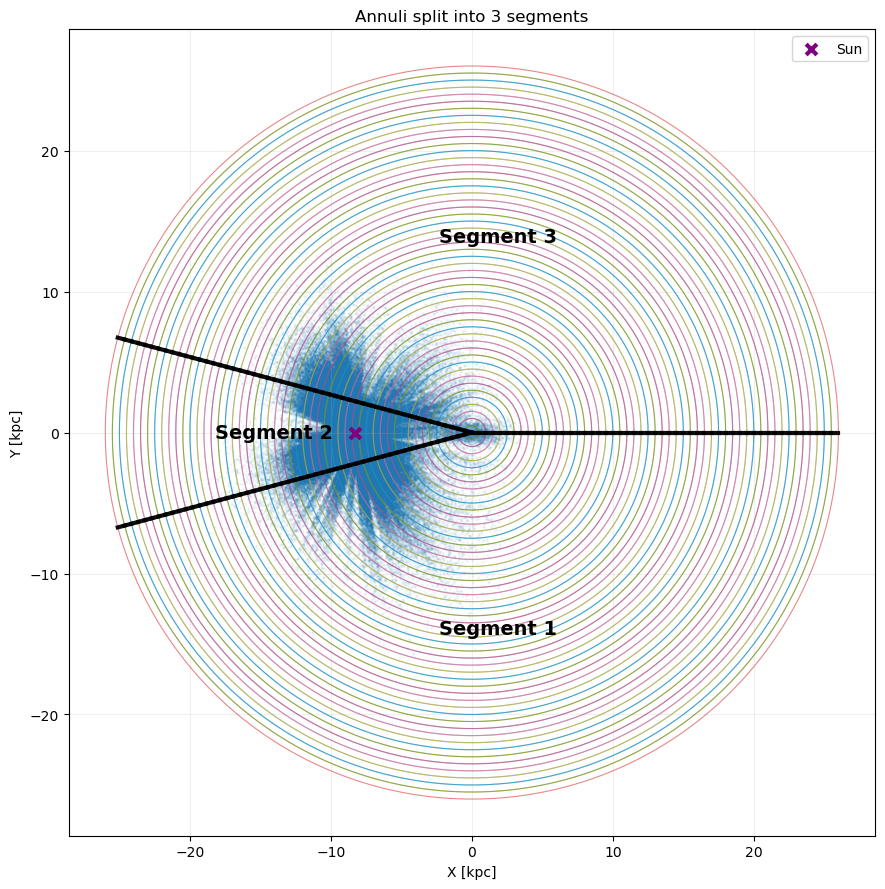

In [86]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FIXED 3-segment split
# ============================================================

phi0 = np.pi                 # wedge points left
dphi = np.deg2rad(15)

b1 = phi0 - dphi
b2 = phi0 + dphi
b3 = phi0 + np.pi            # third line opposite wedge center

plt.figure(figsize=(9, 9))
plt.scatter(Xb, Yb, s=1, alpha=0.05, zorder=1)

theta = np.linspace(0, 2*np.pi, 800)

for (Rmin, Rmax) in annuli:
    # annulus circles
    plt.plot(Rmin*np.cos(theta), Rmin*np.sin(theta), lw=0.8, alpha=0.55, zorder=2)
    plt.plot(Rmax*np.cos(theta), Rmax*np.sin(theta), lw=0.8, alpha=0.55, zorder=2)

    # segment boundaries
    for b in [b1, b2, b3]:
        plt.plot([Rmin*np.cos(b), Rmax*np.cos(b)],
                 [Rmin*np.sin(b), Rmax*np.sin(b)],
                 color="k", lw=3.0, alpha=0.95, zorder=3)

# ------------------------------------------------------------
# Segment labels (placed once, globally)
# ------------------------------------------------------------

# choose a representative radius for text
R_label = np.median([r[0] for r in annuli]) * 1.1

# segment mid-angles
phi_seg2 = phi0                               # narrow wedge
phi_seg1 = 0.5 * (b2 + b3)                    # wide region 1
phi_seg3 = 0.5 * (b3 + b1 + 2*np.pi) % (2*np.pi)  # wide region 3 (wrap-safe)

plt.text(R_label*np.cos(phi_seg1), R_label*np.sin(phi_seg1),
         "Segment 1", fontsize=14, weight="bold",
         ha="center", va="center")

plt.text(R_label*np.cos(phi_seg2), R_label*np.sin(phi_seg2),
         "Segment 2", fontsize=14, weight="bold",
         ha="center", va="center")

plt.text(R_label*np.cos(phi_seg3), R_label*np.sin(phi_seg3),
         "Segment 3", fontsize=14, weight="bold",
         ha="center", va="center")

# ------------------------------------------------------------
# Sun marker
# ------------------------------------------------------------
R0 = 8.275
plt.scatter(-R0, 0, marker="x", s=60, c="purple",
            linewidths=3, zorder=5, label="Sun")

plt.gca().set_aspect("equal", "box")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Annuli split into 3 segments")
plt.grid(alpha=0.2)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

Plotted 32 annuli (annulus total N ≥ 100)


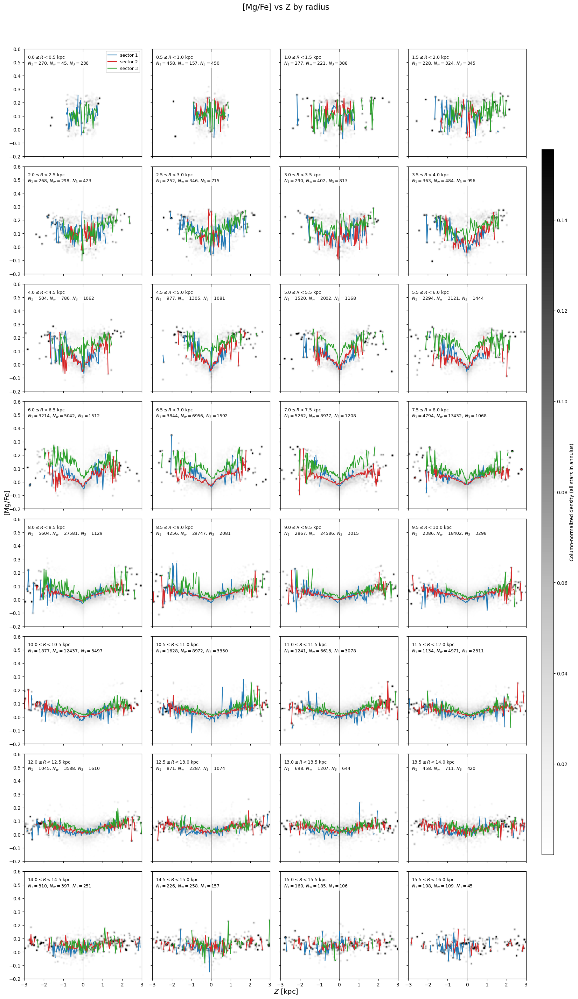

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# -----------------------------
# Controls
# -----------------------------
minN = 100

z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

smooth_sigma = (1.0, 1.0)
cmap_name = "Greys"
vmin_pct, vmax_pct = 2.0, 99.7

def wrap_2pi(a):
    return np.mod(a, 2*np.pi)

def between_ccw_vec(phi, a, b):
    """
    Vectorized: True if phi is on the CCW arc from a to b.
    All angles can be arrays; result is boolean array.
    Works across wrap-around.
    """
    phi = wrap_2pi(phi)
    a   = wrap_2pi(a)
    b   = wrap_2pi(b)

    # CCW arc length from a to b in [0, 2pi)
    arc = wrap_2pi(b - a)
    # displacement from a to phi in [0, 2pi)
    d   = wrap_2pi(phi - a)

    return d < arc

# -----------------------------
# 3-ray split (set these)
# -----------------------------
phi0 = np.pi               # wedge points to -X by default
dphi = np.deg2rad(15)      # wedge half-width

b1 = phi0 - dphi
b2 = phi0 + dphi
b3 = phi0 + np.pi          # third line (opposite wedge)

# If you want to rotate the 3rd line a bit:
# b3 = phi0 + np.pi + np.deg2rad(10)

# wrap boundaries to [0, 2pi)
b1, b2, b3 = wrap_2pi(b1), wrap_2pi(b2), wrap_2pi(b3)

sector_colors = ["tab:blue", "tab:red", "tab:green"]
sector_labels = ["sector 1", "sector 2", "sector 3"]

# ============================================================
# Requires these arrays for your *new-cut* sample:
#   R_all, Z_all, mgfe_all, phi_all
# and annuli = [(Rmin,Rmax), ...] from your annuli builder
# ============================================================

imgs = []
trends_by_ann = []
Ns_by_ann = []
annuli_kept = []

for (Rmin, Rmax) in annuli:
    mR = (R_all >= Rmin) & (R_all < Rmax)

    ZR   = Z_all[mR]
    mgR  = mgfe_all[mR]
    phiR = phi_all[mR]

    finite = np.isfinite(ZR) & np.isfinite(mgR) & np.isfinite(phiR)
    ZR, mgR, phiR = ZR[finite], mgR[finite], wrap_2pi(phiR[finite])

    if len(ZR) < minN:
        continue

    # Background image: all stars in annulus, column-normalized P(Mg/Fe|Z)
    H, _, _ = np.histogram2d(ZR, mgR, bins=[z_edges, mgfe_edges])  # (nz, nmg)
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm  = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T
    imgs.append(img)

    # 3 sectors from the 3 rays:
    # wedge = b1 -> b2 (CCW)
    wedge = between_ccw_vec(phiR, b1, b2)
    sec2  = between_ccw_vec(phiR, b2, b3)
    sec3  = between_ccw_vec(phiR, b3, b1)

    # order = [sec2, wedge, sec3] so wedge is the middle one (red)
    sector_masks = [sec2, wedge, sec3]

    trends = []
    Ns_sec = []

    for sm in sector_masks:
        Zs  = ZR[sm]
        mgs = mgR[sm]
        Ns  = int(len(Zs))
        Ns_sec.append(Ns)

        trend = np.full_like(z_centers, np.nan, dtype=float)
        if Ns >= minN:
            for i in range(len(z_edges) - 1):
                mm = (Zs >= z_edges[i]) & (Zs < z_edges[i+1])
                if np.any(mm):
                    trend[i] = np.nanmean(mgs[mm])
        trends.append(trend)

    trends_by_ann.append(trends)
    Ns_by_ann.append(Ns_sec)
    annuli_kept.append((Rmin, Rmax))

print(f"Plotted {len(annuli_kept)} annuli (annulus total N ≥ {minN})")

# -----------------------------
# Shared color scale
# -----------------------------
if len(imgs) > 0:
    vals = np.concatenate([im[(im > 0) & np.isfinite(im)] for im in imgs])
    if len(vals) > 0:
        vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
    else:
        vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = 0.0, 1.0

# -----------------------------
# Grid layout
# -----------------------------
n_panels = len(annuli_kept)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2*ncols, 3.6*nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

pcm = None

for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    (Rmin, Rmax) = annuli_kept[i]
    img = imgs[i]
    trends = trends_by_ann[i]
    Ns_sec = Ns_by_ann[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )
    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    # 3 sector lines
    for s in range(3):
        ax.plot(
            z_centers, trends[s],
            color=sector_colors[s],
            lw=1.6,
            label=sector_labels[s] if i == 0 else None
        )

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc" + "\n" +
        rf"$N_1={Ns_sec[0]},\,N_w={Ns_sec[1]},\,N_3={Ns_sec[2]}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)

fig.supxlabel(r"$Z$ [kpc]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)
fig.suptitle(r"[Mg/Fe] vs Z by radius", fontsize=16, y=0.995)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density (all stars in annulus)")

axes.flat[0].legend(loc="upper right", fontsize=9, frameon=True)
plt.show()

In [87]:
import numpy as np

# ============================================================
# REQUIREMENTS (must already exist, same length):
#   R_all    [kpc]
#   Z_all    [kpc] (signed)
#   phi_all  [rad] (atan2(Y,X), typically in [-pi, pi])
#   mgfe_all [Mg/Fe]
#
# And your segment boundaries:
#   b1, b2, b3  [rad]
# ============================================================

# -----------------------------
# Settings
# -----------------------------
dR = 0.5
minN_total = 80          # minimum stars in a (annulus,segment) to attempt fit
z_search_min, z_search_max = -2.5, 2.5   # interior range where we search for the minimum
z_hard_min, z_hard_max = -3.0, 3.0       # hard clip for safety

# Local regression controls:
bandwidth = 0.25         # kpc; controls smoothness in Z (try 0.2–0.5)
grid_n = 600             # evaluation grid resolution
min_support = 30         # require at least this many effectively-weighted stars near each z grid point

# -----------------------------
# Helpers for angle sectors
# -----------------------------
def wrap_to_2pi(a):
    a = np.asarray(a)
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    # array-safe: is x between a -> b CCW, with all in [0,2pi)
    x = np.asarray(x)
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks(phi, b1, b2, b3):
    ph = wrap_to_2pi(phi)
    bb1, bb2, bb3 = wrap_to_2pi([b1, b2, b3])
    seg1 = between_ccw(ph, bb1, bb2)
    seg2 = between_ccw(ph, bb2, bb3)
    seg3 = between_ccw(ph, bb3, bb1)
    return {1: seg1, 2: seg2, 3: seg3}

# -----------------------------
# Kernel-weighted local mean curve
# -----------------------------
def local_mean_curve(z, y, z_grid, h, min_support=30):
    """
    Nadaraya–Watson estimator:
      yhat(z0) = sum K((z-z0)/h)*y / sum K((z-z0)/h)
    with Gaussian kernel. Also returns an "effective support" count per grid point.
    """
    z = np.asarray(z)
    y = np.asarray(y)
    z_grid = np.asarray(z_grid)

    # Broadcasted distances: (N, G)
    dz = (z[:, None] - z_grid[None, :]) / h
    w = np.exp(-0.5 * dz**2)   # Gaussian kernel, unnormalized

    wsum = np.sum(w, axis=0)
    yhat = np.sum(w * y[:, None], axis=0) / np.where(wsum > 0, wsum, np.nan)

    # "effective support": convert weights to an approximate local N
    # A simple proxy is count of stars with weight > exp(-0.5*(2)^2)=~0.135 (within ~2h)
    support = np.sum(w > np.exp(-2.0), axis=0)

    # mask low-support points
    yhat[support < min_support] = np.nan
    return yhat, support

# -----------------------------
# Build annuli range
# -----------------------------
finite_all = np.isfinite(R_all) & np.isfinite(Z_all) & np.isfinite(phi_all) & np.isfinite(mgfe_all)
R = np.asarray(R_all)[finite_all]
Z = np.asarray(Z_all)[finite_all]
phi = np.asarray(phi_all)[finite_all]
mgfe = np.asarray(mgfe_all)[finite_all]

# hard Z clip
mZ = (Z >= z_hard_min) & (Z <= z_hard_max)
R, Z, phi, mgfe = R[mZ], Z[mZ], phi[mZ], mgfe[mZ]

Rmin_data = np.nanmin(R)
Rmax_data = np.nanmax(R)
Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR
annuli = [(r0, r0 + dR) for r0 in np.arange(Rstart, Rstop, dR)]

# segment masks on the filtered arrays
segm = segment_masks(phi, b1, b2, b3)

# evaluation grid in Z
z_grid = np.linspace(z_search_min, z_search_max, grid_n)

results = []

for (Rmin, Rmax) in annuli:
    mR = (R >= Rmin) & (R < Rmax)
    if np.sum(mR) == 0:
        continue

    for seg_id in [1, 2, 3]:
        m = mR & segm[seg_id]
        N = int(np.sum(m))

        if N < minN_total:
            results.append({
                "Rmin": Rmin, "Rmax": Rmax, "segment": seg_id, "N": N,
                "z_at_min": np.nan, "mgfe_at_min": np.nan, "status": "too_few_stars"
            })
            continue

        z_s = Z[m]
        y_s = mgfe[m]

        # local regression curve
        yhat, support = local_mean_curve(z_s, y_s, z_grid, h=bandwidth, min_support=min_support)

        if not np.any(np.isfinite(yhat)):
            results.append({
                "Rmin": Rmin, "Rmax": Rmax, "segment": seg_id, "N": N,
                "z_at_min": np.nan, "mgfe_at_min": np.nan, "status": "no_support_in_grid"
            })
            continue

        j = np.nanargmin(yhat)
        results.append({
            "Rmin": Rmin, "Rmax": Rmax, "segment": seg_id, "N": N,
            "z_at_min": float(z_grid[j]),
            "mgfe_at_min": float(yhat[j]),
            "status": "ok"
        })

# -----------------------------
# Print results nicely
# -----------------------------
print("z_at_min results (local regression on stars, no bins)\n")
print("Rmin   Rmax  seg    N   z_at_min   mgfe_at_min  status")
for r in results:
    print(f"{r['Rmin']:5.1f} {r['Rmax']:5.1f}   {r['segment']:1d}  {r['N']:5d}  "
          f"{r['z_at_min']:8.3f}   {r['mgfe_at_min']:10.4f}   {r['status']}")


z_at_min results (local regression on stars, no bins)

Rmin   Rmax  seg    N   z_at_min   mgfe_at_min  status
  0.0   0.5   1     45       nan          nan   too_few_stars
  0.0   0.5   2    270    -0.947       0.0857   ok
  0.0   0.5   3    236    -0.881       0.0967   ok
  0.5   1.0   1    157    -0.346       0.1108   ok
  0.5   1.0   2    458    -0.780       0.1023   ok
  0.5   1.0   3    450    -0.789       0.0909   ok
  1.0   1.5   1    221    -1.031       0.0917   ok
  1.0   1.5   2    277    -0.989       0.0814   ok
  1.0   1.5   3    388    -1.482       0.0951   ok
  1.5   2.0   1    323    -1.023       0.0880   ok
  1.5   2.0   2    228     1.064       0.0906   ok
  1.5   2.0   3    344    -1.432       0.0810   ok
  2.0   2.5   1    298     0.914       0.0903   ok
  2.0   2.5   2    268     0.430       0.0964   ok
  2.0   2.5   3    422    -0.213       0.0818   ok
  2.5   3.0   1    346    -0.881       0.0695   ok
  2.5   3.0   2    249    -0.013       0.0546   ok
  2.5   3.0 

Kept 34 annuli with total N ≥ 100

Minima (z_at_min from local regression) — per annulus & segment
Rmin   Rmax     N1     z1      N2     z2        N3     z3
  0.0   0.5     45     nan     270  -0.947     236  -0.881
  0.5   1.0    157  -0.346     458  -0.780     450  -0.789
  1.0   1.5    221  -1.031     277  -0.989     388  -1.482
  1.5   2.0    324  -1.023     228   1.064     345  -1.432
  2.0   2.5    298   0.914     268   0.430     423  -0.213
  2.5   3.0    346  -0.881     252  -0.013     715  -0.722
  3.0   3.5    402  -0.630     290  -0.021     813  -0.806
  3.5   4.0    484  -0.455     363   0.104     996  -0.780
  4.0   4.5    780  -0.096     504   0.071    1062  -0.680
  4.5   5.0   1305  -0.063     977   0.121    1081  -0.422
  5.0   5.5   2002  -0.046    1520  -0.013    1168   0.013
  5.5   6.0   3121  -0.079    2294  -0.021    1444   0.021
  6.0   6.5   5042  -0.129    3214   0.038    1512  -0.013
  6.5   7.0   6956  -0.096    3844  -0.013    1592   0.038
  7.0   7.5   897

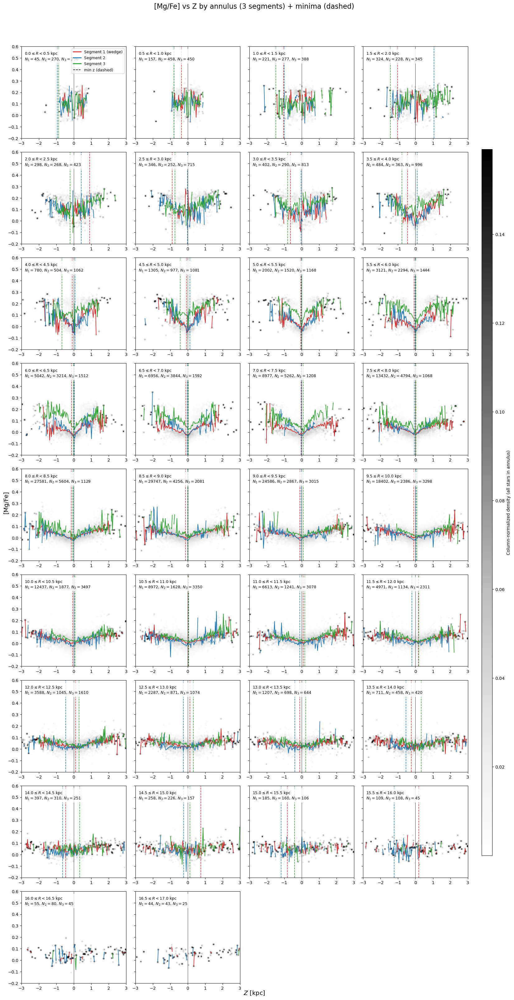

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ============================================================
# USER: choose your final sample here
# ============================================================
t_final = t_poly   # <-- change to t_triangle / t_sel / t_poly as needed

# ============================================================
# 0) Build Galactocentric positions so we have R_all, Z_all, phi_all
# ============================================================
dist = Distance(np.asarray(t_final["r_med_photogeo"], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_final["ra"], float) * u.deg,
    dec=np.asarray(t_final["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_final["pmra"], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_final["pmde"], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_final["v_rad"], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

gc = c.transform_to(galcen_frame)

X = gc.x.to_value(u.kpc)
Y = gc.y.to_value(u.kpc)
Z = gc.z.to_value(u.kpc)

R_all   = np.sqrt(X**2 + Y**2)
phi_all = np.arctan2(Y, X)          # radians, [-pi, pi]

# Chemistry arrays (edit these column names if yours differ)
mgfe_all = (np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float))
feh_all  = np.asarray(t_final["fe_h"], float)

# ============================================================
# 1) Define the 3 fixed segments (narrow wedge + opposite line)
#    Segment 1 = narrow wedge between b1 and b2 (CCW)
# ============================================================
phi0 = np.pi          # wedge centered pointing left (like your sketch)
dphi_deg = 15         # <-- change wedge half-angle here (15 means narrower than 18)
dphi = np.deg2rad(dphi_deg)

b1 = phi0 - dphi
b2 = phi0 + dphi
b3 = phi0 + np.pi     # third line opposite wedge center

def wrap_to_2pi(a):
    a = np.asarray(a)
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    """
    array-safe: True if angle x is between a->b CCW (all in [0,2pi))
    """
    x = np.asarray(x)
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks(phi, b1, b2, b3):
    ph = wrap_to_2pi(phi)
    bb1, bb2, bb3 = wrap_to_2pi([b1, b2, b3])
    seg1 = between_ccw(ph, bb1, bb2)     # narrow wedge
    seg2 = between_ccw(ph, bb2, bb3)
    seg3 = between_ccw(ph, bb3, bb1)
    return {1: seg1, 2: seg2, 3: seg3}

# ============================================================
# 2) Annuli + histogram/trend settings
# ============================================================
dR = 0.5
minN_annulus = 100          # keep annuli only if total N >= this

# background image bins
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

cmap_name = "Greys"
smooth_sigma = (1.0, 1.0)
vmin_pct, vmax_pct = 2.0, 99.7

# ============================================================
# 3) Local regression minimum (for vertical lines)
# ============================================================
z_search_min, z_search_max = -2.5, 2.5
bandwidth = 0.25
grid_n = 600
min_support = 30

def local_mean_curve(z, y, z_grid, h, min_support=30):
    z = np.asarray(z)
    y = np.asarray(y)
    z_grid = np.asarray(z_grid)

    dz = (z[:, None] - z_grid[None, :]) / h
    w = np.exp(-0.5 * dz**2)

    wsum = np.sum(w, axis=0)
    yhat = np.sum(w * y[:, None], axis=0) / np.where(wsum > 0, wsum, np.nan)

    support = np.sum(w > np.exp(-2.0), axis=0)  # within ~2h
    yhat[support < min_support] = np.nan
    return yhat, support

z_grid = np.linspace(z_search_min, z_search_max, grid_n)

# ============================================================
# 4) Filter finite + build lists (annuli/imgs/trends/Ns)
# ============================================================
finite_all = (
    np.isfinite(R_all) & np.isfinite(Z) & np.isfinite(phi_all) &
    np.isfinite(mgfe_all)
)
R = R_all[finite_all]
Z = Z[finite_all]
phi = phi_all[finite_all]
mgfe = mgfe_all[finite_all]

segm = segment_masks(phi, b1, b2, b3)

Rmin_data = np.nanmin(R)
Rmax_data = np.nanmax(R)
Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR
all_annuli = [(r0, r0 + dR) for r0 in np.arange(Rstart, Rstop, dR)]

annuli = []
imgs = []
mean_trends = []      # list of dicts: {1:trend1,2:trend2,3:trend3}
Ns_by_segment = []    # list of dicts: {1:N1,2:N2,3:N3}
zmins_by_segment = [] # list of dicts: {1:zmin1,2:zmin2,3:zmin3} (may be nan)

# build panel products
for (Rmin, Rmax) in all_annuli:
    mR = (R >= Rmin) & (R < Rmax)
    Ntot = int(np.sum(mR))
    if Ntot < minN_annulus:
        continue

    Zr = Z[mR]
    mgr = mgfe[mR]

    # ---- background image: P(Mg/Fe | Z) using ALL stars in annulus
    finite = np.isfinite(Zr) & np.isfinite(mgr)
    Zr = Zr[finite]
    mgr = mgr[finite]
    if len(Zr) < minN_annulus:
        continue

    H, _, _ = np.histogram2d(Zr, mgr, bins=[z_edges, mgfe_edges])  # (nz,nmgfe)
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm  = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T

    # ---- mean trend per segment (binned mean)
    trends = {}
    Ns = {}
    zmins = {}

    for seg_id in [1, 2, 3]:
        m = mR & segm[seg_id]
        Ns[seg_id] = int(np.sum(m))
        Zs = Z[m]
        Ys = mgfe[m]
        good = np.isfinite(Zs) & np.isfinite(Ys)
        Zs = Zs[good]
        Ys = Ys[good]

        # binned mean line for plotting
        trend = np.full_like(z_centers, np.nan, dtype=float)
        for i in range(len(z_edges) - 1):
            mm = (Zs >= z_edges[i]) & (Zs < z_edges[i+1])
            if np.any(mm):
                trend[i] = np.nanmean(Ys[mm])
        trends[seg_id] = trend

        # smooth local-regression minimum (for vertical line)
        if len(Zs) < max(80, min_support):
            zmins[seg_id] = np.nan
        else:
            yhat, support = local_mean_curve(Zs, Ys, z_grid, h=bandwidth, min_support=min_support)
            if np.any(np.isfinite(yhat)):
                j = np.nanargmin(yhat)
                zmins[seg_id] = float(z_grid[j])
            else:
                zmins[seg_id] = np.nan

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trends)
    Ns_by_segment.append(Ns)
    zmins_by_segment.append(zmins)

print(f"Kept {len(annuli)} annuli with total N ≥ {minN_annulus}")

# ============================================================
# 5) Shared color scale
# ============================================================
if len(imgs) > 0:
    vals = np.concatenate([im[(im > 0) & np.isfinite(im)] for im in imgs])
    if len(vals) > 0:
        vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
    else:
        vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = 0.0, 1.0

# ============================================================
# 6) Print minima table (this is what you asked for earlier)
# ============================================================
print("\nMinima (z_at_min from local regression) — per annulus & segment")
print("Rmin   Rmax     N1     z1      N2     z2        N3     z3")
for i, (Rmin, Rmax) in enumerate(annuli):
    Ns = Ns_by_segment[i]
    zm = zmins_by_segment[i]
    print(f"{Rmin:5.1f} {Rmax:5.1f}  "
          f"{Ns[1]:5d} {zm[1]:7.3f}   "
          f"{Ns[2]:5d} {zm[2]:7.3f}   "
          f"{Ns[3]:5d} {zm[3]:7.3f}")

# ============================================================
# 7) Multi-panel figure (original style) + vertical lines at zmins
# ============================================================
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

pcm = None
colors = {1: "tab:red", 2: "tab:blue", 3: "tab:green"}

for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trends = mean_trends[i]
    Ns = Ns_by_segment[i]
    zm = zmins_by_segment[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    # mean binned lines
    for seg_id in [1, 2, 3]:
        ax.plot(z_centers, trends[seg_id], color=colors[seg_id], lw=1.3)

    # vertical lines where minimum is (if finite)
    for seg_id in [1, 2, 3]:
        if np.isfinite(zm[seg_id]):
            ax.axvline(zm[seg_id], color=colors[seg_id], ls="--", lw=1.2, alpha=0.9)

    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc"
        + "\n"
        + rf"$N_1={Ns[1]},\,N_2={Ns[2]},\,N_3={Ns[3]}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)
    ax.tick_params(axis="x", which="both", labelbottom=True)

fig.supxlabel(r"$Z$ [kpc]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)
fig.suptitle(r"[Mg/Fe] vs Z by annulus (3 segments) + minima (dashed)", fontsize=16, y=0.995)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density (all stars in annulus)")

# legend once
axes.flat[0].plot([], [], color=colors[1], lw=2, label="Segment 1 (wedge)")
axes.flat[0].plot([], [], color=colors[2], lw=2, label="Segment 2")
axes.flat[0].plot([], [], color=colors[3], lw=2, label="Segment 3")
axes.flat[0].plot([], [], color="k", ls="--", lw=1.2, label="min z (dashed)")
axes.flat[0].legend(loc="upper right", fontsize=9, frameon=True)

plt.show()


Stars with assigned zmin color: 276104 / 276750


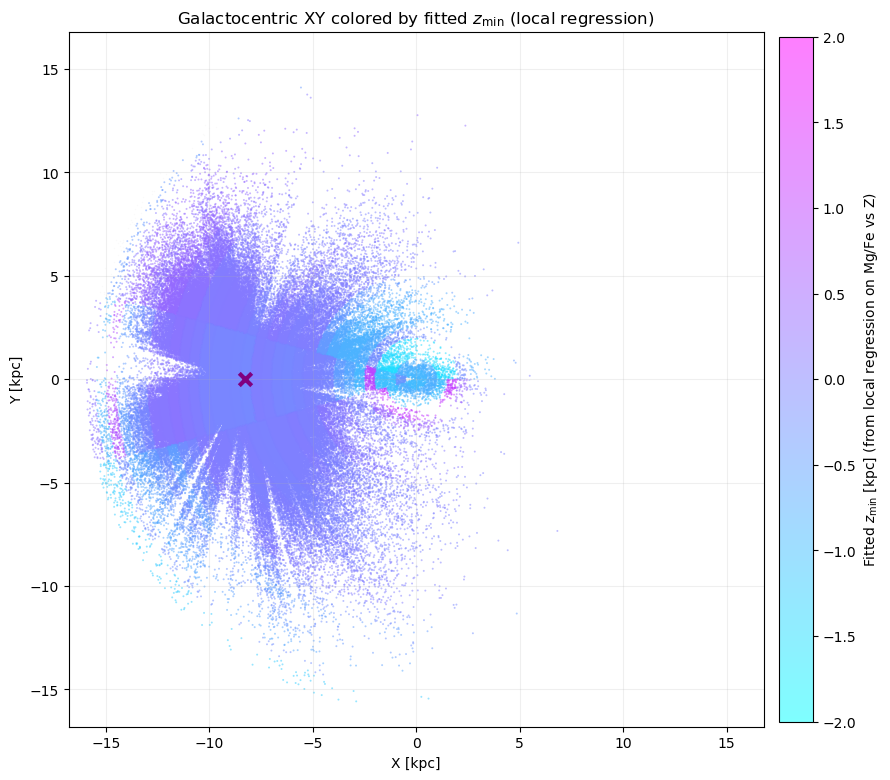

In [118]:
# ============================================================
# 8) XY MAP: color each star by z_at_min for its (annulus, segment)
#    (using the LOCAL REGRESSION zmins_by_segment you already computed)
# ============================================================

# --- controls ---
Rmax_xy = 16.0                 # only show stars with R <= this
cmap_xy = "cool"           # try: "RdBu_r", "viridis", "plasma"
alpha_pts = 0.50
s_pts = 2
show_context = True            # show faint background points with no assigned zmin?

# optional fixed color limits
vmin_xy, vmax_xy = -2.0, 2.0   # set to None/None to auto

# ------------------------------------------------------------
# Build lookup: (Rmin,Rmax,seg) -> zmin
# IMPORTANT: use the EXACT (Rmin,Rmax) tuples in annuli[]
# ------------------------------------------------------------
zmin_lookup = {}
for i, (Rmin, Rmax) in enumerate(annuli):
    zm = zmins_by_segment[i]
    for seg_id in [1, 2, 3]:
        zmin_lookup[(float(Rmin), float(Rmax), int(seg_id))] = float(zm[seg_id]) if np.isfinite(zm[seg_id]) else np.nan

# ------------------------------------------------------------
# Assign each star its annulus (Rmin,Rmax) and segment id
# We are using the filtered arrays X,Y,R,phi,mgfe defined in your code.
# segm is already computed on these filtered arrays.
# ------------------------------------------------------------
seg_id = np.zeros(len(R), dtype=int)
seg_id[segm[1]] = 1
seg_id[segm[2]] = 2
seg_id[segm[3]] = 3

# annulus edges from Rstart/dR (same binning used to build all_annuli)
ann_idx = np.floor((R - Rstart) / dR).astype(int)
Rmin_star = Rstart + ann_idx * dR
Rmax_star = Rmin_star + dR

# map to zmin color
z_color = np.full(len(R), np.nan, dtype=float)
for j in range(len(R)):
    if R[j] > Rmax_xy:
        continue
    s = seg_id[j]
    if s not in (1, 2, 3):
        continue
    key = (float(Rmin_star[j]), float(Rmax_star[j]), int(s))
    z_color[j] = zmin_lookup.get(key, np.nan)

# stars that got a valid color
m_col = np.isfinite(z_color) & (R <= Rmax_xy)

print("Stars with assigned zmin color:", int(np.sum(m_col)), "/", len(R))

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 9))

# faint context (optional): stars with no assigned zmin
if show_context:
    m_ctx = (~m_col) & (R <= Rmax_xy)
    if np.any(m_ctx):
        ax.scatter(X[m_ctx], Y[m_ctx], s=1, alpha=0.02, color="k", linewidths=0)

sc = ax.scatter(
    X[m_col], Y[m_col],
    c=z_color[m_col],
    s=s_pts,
    alpha=alpha_pts,
    cmap=cmap_xy,
    vmin=vmin_xy, vmax=vmax_xy,
    linewidths=0
)

# Sun marker (optional)
R0 = 8.275
ax.scatter(-R0, 0, marker="x", s=80, c="purple", linewidths=3, zorder=10)

ax.set_aspect("equal", "box")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_title(r"Galactocentric XY colored by fitted $z_{\min}$ (local regression)")

ax.grid(alpha=0.2)

cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.02)
cbar.set_label(r"Fitted $z_{\min}$ [kpc] (from local regression on Mg/Fe vs Z)")

lim = Rmax_xy * 1.05
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)

plt.tight_layout()
plt.show()

Built 32 annuli panels (Rmax <= 16.0 kpc).

Minima (quadratic regression on mean-line inside Z window)
Rmin  Rmax   seg   Nseg   z_at_min   status
 0.0  0.5   1      45        nan   too_few_stars
 0.0  0.5   2     270      2.500   ok
 0.0  0.5   3     236     -0.231   ok
 0.5  1.0   1     157     -2.500   ok
 0.5  1.0   2     458      0.929   ok
 0.5  1.0   3     450     -0.176   ok
 1.0  1.5   1     221      0.289   ok
 1.0  1.5   2     277      2.500   ok
 1.0  1.5   3     388     -1.007   ok
 1.5  2.0   1     323      0.160   ok
 1.5  2.0   2     228     -1.933   ok
 1.5  2.0   3     344      2.500   ok
 2.0  2.5   1     298      0.167   ok
 2.0  2.5   2     268     -0.370   ok
 2.0  2.5   3     422     -0.235   ok
 2.5  3.0   1     346     -0.024   ok
 2.5  3.0   2     249      0.136   ok
 2.5  3.0   3     715     -0.470   ok
 3.0  3.5   1     402     -0.199   ok
 3.0  3.5   2     289      0.013   ok
 3.0  3.5   3     812     -0.508   ok
 3.5  4.0   1     484     -0.411   ok
 3.5  

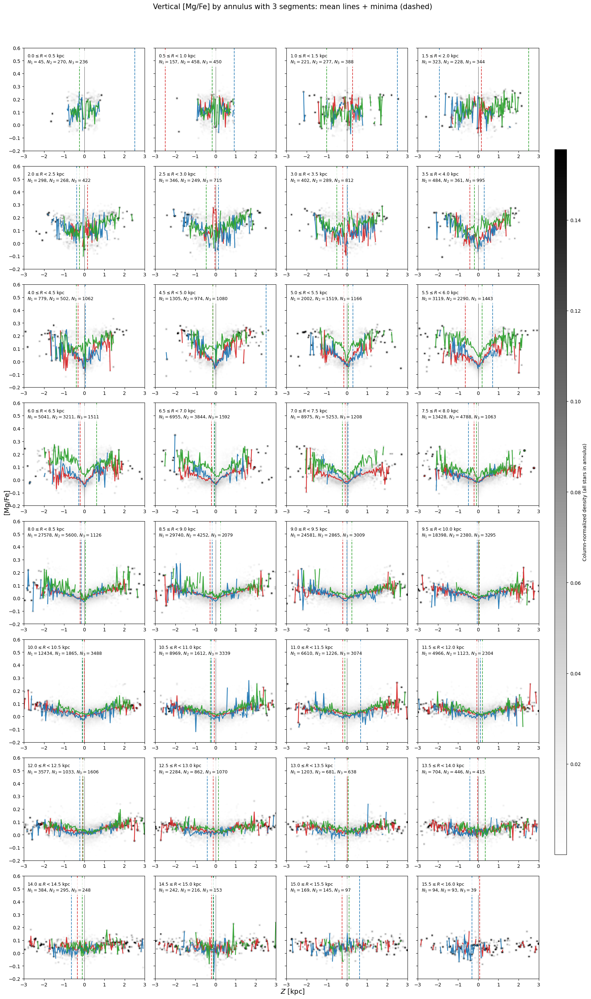

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# ============================================================
# FULL MULTI-PANEL PLOT (annuli x 3 segments) WITH:
#  - column-normalized Mg/Fe vs Z density background (all stars in annulus)
#  - 3 mean-trend lines (one per segment)
#  - vertical dashed lines at z_at_min for each segment
#  - robust handling of how "trend" is stored (y-only, (z,y), (z,y,...) )
#
# REQUIREMENTS (must already exist, same length):
#   R_all    [kpc]
#   Z_all    [kpc]  (signed)
#   phi_all  [rad]  (atan2(Y,X), typically in [-pi, pi])
#   mgfe_all [Mg/Fe]
#
# AND your segment boundaries (radians):
#   b1, b2, b3
# ============================================================

# -----------------------------
# Settings (edit if you want)
# -----------------------------
dR = 0.5
Rmax_use = 16.0          # only plot panels with Rmax <= this
minN_annulus = 100       # minimum stars in annulus to include panel
minN_seg = 80            # minimum stars in (annulus, segment) to compute segment mean-line
cmap_name = "Greys"

# Z and Mg/Fe bins for background density (shared across panels)
z_edges    = np.linspace(-3.0, 3.0, 181)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

# background smoothing (image only)
smooth_sigma = (1.0, 1.0)

# Robust color scaling for background
vmin_pct, vmax_pct = 2.0, 99.7

# Segment line colors (match your convention)
seg_colors = {1: "tab:red", 2: "tab:blue", 3: "tab:green"}

# Min-finding controls (simple, robust)
z_search_min, z_search_max = -2.5, 2.5    # don't consider endpoints
min_valid_bins_for_min = 10               # require at least this many finite mean points in search window
poly_deg = 2                              # quadratic fit to mean-line vs Z (simple regression)


# ============================================================
# Helpers
# ============================================================
def wrap_to_2pi(a):
    a = np.asarray(a)
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    # array-safe: is x between a -> b CCW, with all in [0,2pi)
    x = np.asarray(x)
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks(phi, b1, b2, b3):
    ph = wrap_to_2pi(phi)
    bb1, bb2, bb3 = wrap_to_2pi([b1, b2, b3])
    seg1 = between_ccw(ph, bb1, bb2)
    seg2 = between_ccw(ph, bb2, bb3)
    seg3 = between_ccw(ph, bb3, bb1)
    return {1: seg1, 2: seg2, 3: seg3}

def unpack_trend(trend_obj, z_default):
    """
    Returns (zline, yline) from trend_obj.
    Accepts:
      - yline only (1D array)
      - (zline, yline)
      - (zline, yline, anything_else...)
    """
    if isinstance(trend_obj, (tuple, list)):
        if len(trend_obj) >= 2:
            return np.asarray(trend_obj[0]), np.asarray(trend_obj[1])
        else:
            return np.asarray(z_default), np.asarray(trend_obj[0])
    else:
        return np.asarray(z_default), np.asarray(trend_obj)

def mean_line_binned(Z, y, z_edges):
    """
    Mean y in each Z bin (returns yline aligned with z_centers).
    """
    yline = np.full(len(z_edges) - 1, np.nan, dtype=float)
    for i in range(len(z_edges) - 1):
        m = (Z >= z_edges[i]) & (Z < z_edges[i+1])
        if np.any(m):
            yline[i] = np.nanmean(y[m])
    return yline

def find_min_z_from_meanline(zline, yline,
                            zmin=z_search_min, zmax=z_search_max,
                            min_valid=min_valid_bins_for_min,
                            deg=poly_deg):
    """
    Find z coordinate where mean-line reaches its minimum,
    using a quadratic regression fit to the mean-line inside [zmin, zmax].
    Returns z_at_min (float) and mgfe_at_min (float) or (nan,nan) if failed.
    """
    zline = np.asarray(zline)
    yline = np.asarray(yline)

    m = np.isfinite(zline) & np.isfinite(yline) & (zline >= zmin) & (zline <= zmax)
    if np.sum(m) < min_valid:
        return np.nan, np.nan, "too_few_points"

    zz = zline[m]
    yy = yline[m]

    # regression fit (poly)
    try:
        p = np.polyfit(zz, yy, deg=deg)
    except Exception:
        return np.nan, np.nan, "polyfit_failed"

    # For quadratic: y = a z^2 + b z + c => min at z* = -b/(2a)
    if deg == 2:
        a, b, c = p
        if not np.isfinite(a) or np.abs(a) < 1e-12:
            # fallback: just take discrete min
            j = np.nanargmin(yy)
            return float(zz[j]), float(yy[j]), "fallback_discrete_min"
        z_star = -b / (2*a)
        # clamp to search window
        z_star = float(np.clip(z_star, zmin, zmax))
        y_star = float(np.polyval(p, z_star))
        return z_star, y_star, "ok"
    else:
        # generic: evaluate on fine grid and pick min
        grid = np.linspace(zmin, zmax, 600)
        yhat = np.polyval(p, grid)
        j = np.nanargmin(yhat)
        return float(grid[j]), float(yhat[j]), "ok_grid"


# ============================================================
# Prepare filtered arrays
# ============================================================
finite = np.isfinite(R_all) & np.isfinite(Z_all) & np.isfinite(phi_all) & np.isfinite(mgfe_all)
R = np.asarray(R_all)[finite]
Z = np.asarray(Z_all)[finite]
phi = np.asarray(phi_all)[finite]
mgfe = np.asarray(mgfe_all)[finite]

# clip Z for safety (matches plotting window)
mZ = (Z >= -3.0) & (Z <= 3.0)
R, Z, phi, mgfe = R[mZ], Z[mZ], phi[mZ], mgfe[mZ]

# segment masks on filtered arrays
segm = segment_masks(phi, b1, b2, b3)

# ============================================================
# Build annuli list up to Rmax_use
# ============================================================
Rmin_data = np.nanmin(R)
Rmax_data = np.nanmin([np.nanmax(R), Rmax_use])

Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR

all_annuli = [(r0, r0 + dR) for r0 in np.arange(Rstart, Rstop, dR) if (r0 + dR) <= Rmax_use]

# ============================================================
# Build panel products:
#   - background image per annulus (all stars in annulus)
#   - mean-trend lines per segment
#   - minima z per segment
#   - Ns per segment
# ============================================================
annuli = []
imgs = []
mean_trends = []   # list of dicts: {1: (z,y), 2: (z,y), 3: (z,y)}
Ns_by_segment = [] # list of dicts: {1:N1,2:N2,3:N3}
zmins_by_segment = []  # list of dicts: {1:zmin,2:zmin,3:zmin}
status_by_segment = [] # list of dicts: {1:status,...}

for (Rmin, Rmax) in all_annuli:
    mR = (R >= Rmin) & (R < Rmax)
    Ntot = int(np.sum(mR))
    if Ntot < minN_annulus:
        continue

    Zr = Z[mR]
    mgr = mgfe[mR]

    # background: P(Mg/Fe | Z) column-normalized
    H, _, _ = np.histogram2d(Zr, mgr, bins=[z_edges, mgfe_edges])  # (nz, nmg)
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=smooth_sigma).T  # transpose => mgfe vertical

    # per-segment mean lines + minima
    trends = {}
    Nsseg = {}
    zmins = {}
    stats = {}

    for seg in [1, 2, 3]:
        m = mR & segm[seg]
        N = int(np.sum(m))
        Nsseg[seg] = N

        if N < minN_seg:
            trends[seg] = (z_centers, np.full_like(z_centers, np.nan, dtype=float))
            zmins[seg] = np.nan
            stats[seg] = "too_few_stars"
            continue

        z_s = Z[m]
        y_s = mgfe[m]

        yline = mean_line_binned(z_s, y_s, z_edges)  # aligned with z_centers
        trends[seg] = (z_centers, yline)

        z_at_min, y_at_min, st = find_min_z_from_meanline(z_centers, yline)
        zmins[seg] = z_at_min
        stats[seg] = st

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trends)
    Ns_by_segment.append(Nsseg)
    zmins_by_segment.append(zmins)
    status_by_segment.append(stats)

print(f"Built {len(annuli)} annuli panels (Rmax <= {Rmax_use} kpc).")

# ============================================================
# Shared background color scale
# ============================================================
if len(imgs) > 0:
    vals = np.concatenate([im[(im > 0) & np.isfinite(im)] for im in imgs])
    if len(vals) > 0:
        vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
    else:
        vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = 0.0, 1.0

# ============================================================
# Print minima table (requested)
# ============================================================
print("\nMinima (quadratic regression on mean-line inside Z window)")
print("Rmin  Rmax   seg   Nseg   z_at_min   status")
for i, (Rmin, Rmax) in enumerate(annuli):
    for seg in [1, 2, 3]:
        N = Ns_by_segment[i][seg]
        zmin = zmins_by_segment[i][seg]
        st = status_by_segment[i][seg]
        print(f"{Rmin:4.1f} {Rmax:4.1f}   {seg:d}   {N:5d}   {zmin:8.3f}   {st}")

# ============================================================
# MULTI-PANEL PLOT (with vertical minima lines)
# ============================================================
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.3 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

pcm = None
for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trends = mean_trends[i]
    Nsseg = Ns_by_segment[i]
    zmins = zmins_by_segment[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    # vertical line at Z=0
    ax.axvline(0, color="k", lw=0.8, alpha=0.6)

    # plot mean lines per segment + vertical minima lines
    for seg in [1, 2, 3]:
        zline, yline = unpack_trend(trends[seg], z_default=z_centers)
        ax.plot(zline, yline, color=seg_colors[seg], lw=1.7, alpha=0.95)

        if np.isfinite(zmins[seg]):
            ax.axvline(zmins[seg], color=seg_colors[seg], ls="--", lw=1.4, alpha=0.85)

    # panel label
    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc" + "\n" +
        rf"$N_1={Nsseg[1]},\,N_2={Nsseg[2]},\,N_3={Nsseg[3]}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)

    # show x tick labels on every panel (if you want)
    ax.tick_params(axis="x", which="both", labelbottom=True)

# shared labels/title
fig.supxlabel(r"$Z$ [kpc]", fontsize=14)
fig.supylabel(r"[Mg/Fe]", fontsize=14)
fig.suptitle(r"Vertical [Mg/Fe] by annulus with 3 segments: mean lines + minima (dashed)", fontsize=15, y=0.995)

# colorbar
fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density (all stars in annulus)")

plt.show()


Stars colored: 275671  /  276176


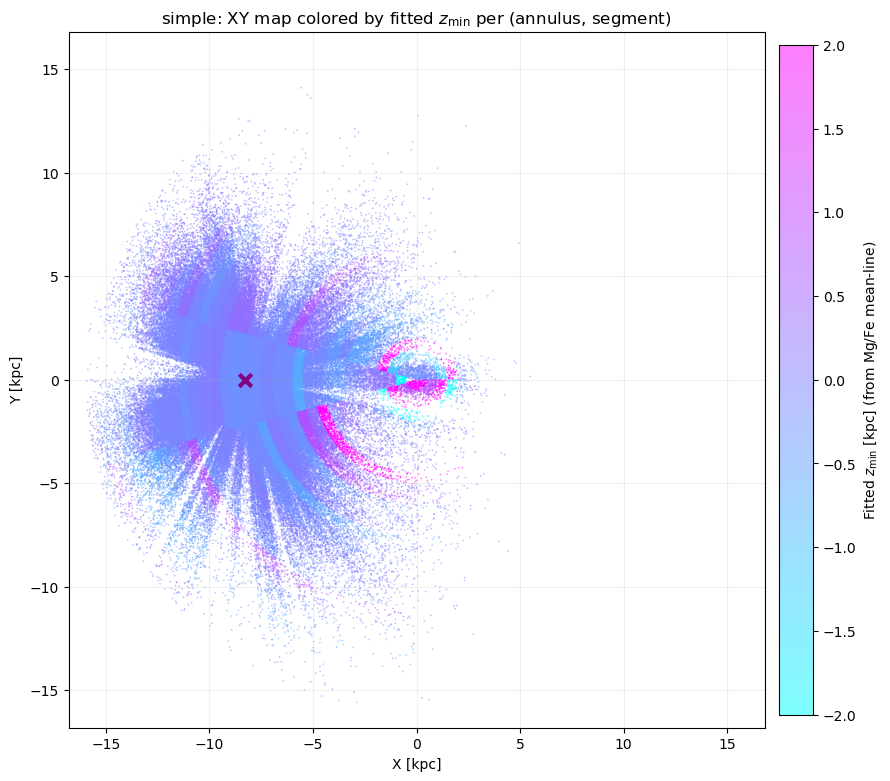

In [113]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# REQUIREMENTS (must already exist, same length):
#   X_all, Y_all   [kpc]  (Galactocentric)
#   R_all          [kpc]
#   Z_all          [kpc]  (signed)
#   phi_all        [rad]  (atan2(Y,X), usually [-pi, pi])
#   mgfe_all       [Mg/Fe]  (not used here, but your pipeline likely has it)
#
# Segment boundaries (radians):
#   b1, b2, b3
#
# Also: you already "did the fitting we just did" -> this cell
# will re-compute z_at_min in the same simple quadratic-on-meanline way,
# then paint the XY map using those z_at_min values.
# ============================================================

# -----------------------------
# USER SETTINGS
# -----------------------------
dR = 0.5
Rmax_use = 16.0

# include a panel only if annulus has enough stars (for fit stability)
minN_annulus = 100
minN_seg = 80

# Z-bin mean line + quadratic min (same as your “simpler” method)
z_edges = np.linspace(-3.0, 3.0, 181)
z_centers = 0.5 * (z_edges[:-1] + z_edges[1:])
z_search_min, z_search_max = -2.5, 2.5
min_valid_bins_for_min = 10

# XY display controls
alpha_pts = 0.5
s_pts = 1.5

# draw rings + boundaries?
draw_annuli = False
draw_segment_lines = False

# color limits for z_at_min map (set None to auto from data)
vmin, vmax = -2.0, 2.0


# ============================================================
# Helpers
# ============================================================
def wrap_to_2pi(a):
    a = np.asarray(a)
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    x = np.asarray(x)
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks(phi, b1, b2, b3):
    ph = wrap_to_2pi(phi)
    bb1, bb2, bb3 = wrap_to_2pi([b1, b2, b3])
    seg1 = between_ccw(ph, bb1, bb2)
    seg2 = between_ccw(ph, bb2, bb3)
    seg3 = between_ccw(ph, bb3, bb1)
    return {1: seg1, 2: seg2, 3: seg3}

def mean_line_binned(Z, y, z_edges):
    yline = np.full(len(z_edges) - 1, np.nan, dtype=float)
    for i in range(len(z_edges) - 1):
        m = (Z >= z_edges[i]) & (Z < z_edges[i+1])
        if np.any(m):
            yline[i] = np.nanmean(y[m])
    return yline

def find_min_z_quadratic(zline, yline,
                         zmin=z_search_min, zmax=z_search_max,
                         min_valid=min_valid_bins_for_min):
    zline = np.asarray(zline)
    yline = np.asarray(yline)

    m = np.isfinite(zline) & np.isfinite(yline) & (zline >= zmin) & (zline <= zmax)
    if np.sum(m) < min_valid:
        return np.nan, "too_few_points"

    zz = zline[m]
    yy = yline[m]

    # quadratic fit: y = a z^2 + b z + c
    try:
        a, b, c = np.polyfit(zz, yy, deg=2)
    except Exception:
        j = np.nanargmin(yy)
        return float(zz[j]), "fallback_discrete"

    if not np.isfinite(a) or np.abs(a) < 1e-12:
        j = np.nanargmin(yy)
        return float(zz[j]), "fallback_discrete"

    z_star = -b / (2*a)
    z_star = float(np.clip(z_star, zmin, zmax))
    return z_star, "ok"


# ============================================================
# Filter arrays consistently
# ============================================================
finite = (
    np.isfinite(X_all) & np.isfinite(Y_all) &
    np.isfinite(R_all) & np.isfinite(Z_all) &
    np.isfinite(phi_all)
)
X = np.asarray(X_all)[finite]
Y = np.asarray(Y_all)[finite]
R = np.asarray(R_all)[finite]
Z = np.asarray(Z_all)[finite]
phi = np.asarray(phi_all)[finite]

# we need Mg/Fe just to build the mean line if you want to re-fit here.
# If you want to *only* use previously-computed zmins table, say so and we’ll skip this.
mgfe = np.asarray(mgfe_all)[finite]

# keep within Z window used for the mean lines (optional but recommended)
mZ = (Z >= -3.0) & (Z <= 3.0)
X, Y, R, Z, phi, mgfe = X[mZ], Y[mZ], R[mZ], Z[mZ], phi[mZ], mgfe[mZ]

segm = segment_masks(phi, b1, b2, b3)

# ============================================================
# Build annuli list up to 16 kpc
# ============================================================
Rmax_data = min(np.nanmax(R), Rmax_use)
Rmin_data = np.nanmin(R)

Rstart = np.floor(Rmin_data / dR) * dR
Rstop  = np.ceil(Rmax_data / dR) * dR
annuli = [(r0, r0 + dR) for r0 in np.arange(Rstart, Rstop, dR) if (r0 + dR) <= Rmax_use]

# ============================================================
# Fit z_at_min for each (annulus, segment)
# ============================================================
zmin_lookup = {}   # key: (Rmin, Rmax, seg) -> z_at_min

for (Rmin, Rmax) in annuli:
    mR = (R >= Rmin) & (R < Rmax)
    Ntot = int(np.sum(mR))
    if Ntot < minN_annulus:
        continue

    for seg in [1, 2, 3]:
        m = mR & segm[seg]
        N = int(np.sum(m))
        if N < minN_seg:
            zmin_lookup[(Rmin, Rmax, seg)] = np.nan
            continue

        # mean Mg/Fe line in Z bins for this (annulus, seg)
        yline = mean_line_binned(Z[m], mgfe[m], z_edges)
        z_at_min, status = find_min_z_quadratic(z_centers, yline)
        zmin_lookup[(Rmin, Rmax, seg)] = z_at_min

# ============================================================
# Assign each star a z_color = z_at_min(its annulus, seg)
# ============================================================
# figure out annulus index per star
ann_idx = np.floor((R - Rstart) / dR).astype(int)
Rmin_star = Rstart + ann_idx * dR
Rmax_star = Rmin_star + dR

# segment id per star (1/2/3)
seg_id = np.zeros(len(R), dtype=int)
seg_id[segm[1]] = 1
seg_id[segm[2]] = 2
seg_id[segm[3]] = 3

z_color = np.full(len(R), np.nan, dtype=float)
for i in range(len(R)):
    Rmi = float(Rmin_star[i])
    Rma = float(Rmax_star[i])
    s = int(seg_id[i])
    # enforce within range and only annuli we used
    if (Rma <= Rmax_use) and (s in [1,2,3]):
        z_color[i] = zmin_lookup.get((Rmi, Rma, s), np.nan)

# only plot stars that got an assigned value
mplot = np.isfinite(z_color) & (Rmax_star <= Rmax_use)

print("Stars colored:", int(np.sum(mplot)), " / ", len(R))

# ============================================================
# Plot XY colored by the fitted z_at_min per region
# ============================================================
fig, ax = plt.subplots(figsize=(9, 9))

sc = ax.scatter(
    X[mplot], Y[mplot],
    c=z_color[mplot],
    s=s_pts, alpha=alpha_pts,
    cmap="cool",   # change if you want
    vmin=vmin, vmax=vmax,
    linewidths=0
)

# optional: show uncolored context very faint
mctx = (~mplot) & (R <= Rmax_use)
if np.any(mctx):
    ax.scatter(X[mctx], Y[mctx], s=1, alpha=0.02, color="k", linewidths=0)

# draw annuli and boundaries
theta = np.linspace(0, 2*np.pi, 600)

if draw_annuli:
    # light thin rings
    for (Rmin, Rmax) in annuli:
        ax.plot(Rmin*np.cos(theta), Rmin*np.sin(theta), lw=0.6, alpha=0.15, color="k")
    # outer edge
    ax.plot(Rmax_use*np.cos(theta), Rmax_use*np.sin(theta), lw=0.8, alpha=0.2, color="k")

if draw_segment_lines:
    # draw the 3 rays once (same angles for all annuli)
    for b in [b1, b2, b3]:
        ax.plot([0, Rmax_use*np.cos(b)], [0, Rmax_use*np.sin(b)], color="k", lw=2.2, alpha=0.7)

# Sun marker (Galactocentric x = -R0)
R0 = 8.275
ax.scatter(-R0, 0, marker="x", s=80, c="purple", linewidths=3, zorder=10)

ax.set_aspect("equal", "box")
ax.set_xlabel("X [kpc]")
ax.set_ylabel("Y [kpc]")
ax.set_title("simple: XY map colored by fitted $z_{\\min}$ per (annulus, segment)")
ax.grid(alpha=0.2)

cbar = plt.colorbar(sc, ax=ax, fraction=0.045, pad=.02)
cbar.set_label(r"Fitted $z_{\min}$ [kpc] (from Mg/Fe mean-line)")

lim = Rmax_use * 1.05
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)

plt.tight_layout()
plt.show()


Kept 32 annuli with Ntot ≥ 100 and R < 16.0 kpc

Picked minima from binned mean line (interior only + support + trim + smooth)

Rmin   Rmax     N1   z1     (st1)     N2   z2     (st2)     N3   z3     (st3)
  0.0   0.5     45    nan ( too_few_stars)     270 -0.550 (            ok)     236 -0.450 (            ok)
  0.5   1.0    157 -0.350 (            ok)     458  0.250 (            ok)     450 -0.550 (            ok)
  1.0   1.5    221 -0.350 (            ok)     277  0.250 (            ok)     388 -0.550 (            ok)
  1.5   2.0    324 -0.450 (            ok)     228  0.350 (            ok)     345 -0.850 (            ok)
  2.0   2.5    298  0.050 (            ok)     268 -0.550 (            ok)     423 -0.350 (            ok)
  2.5   3.0    346 -0.350 (            ok)     252 -0.350 (            ok)     715 -0.650 (            ok)
  3.0   3.5    402 -0.450 (            ok)     290 -0.350 (            ok)     813 -0.150 (            ok)
  3.5   4.0    484 -0.050 (            ok)   

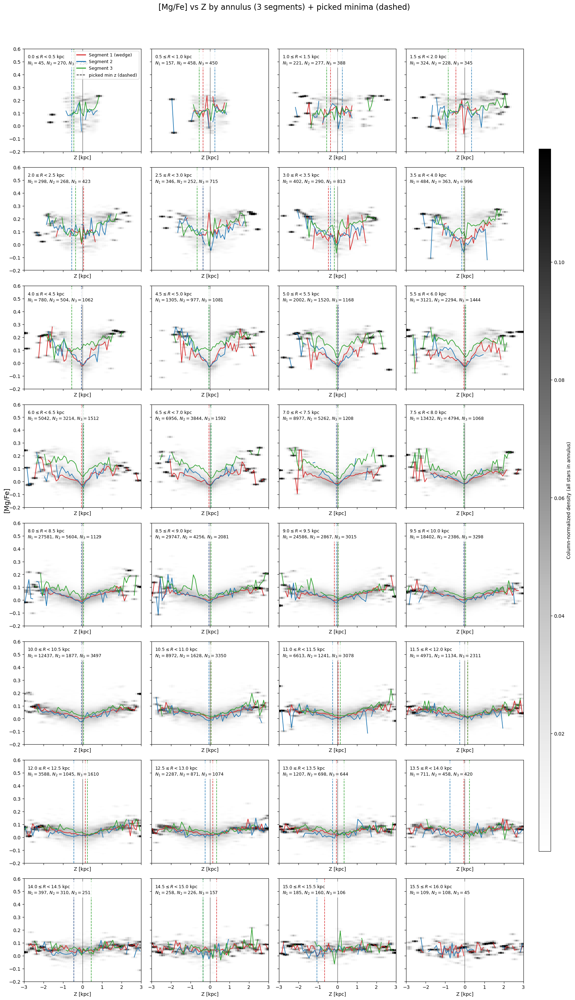

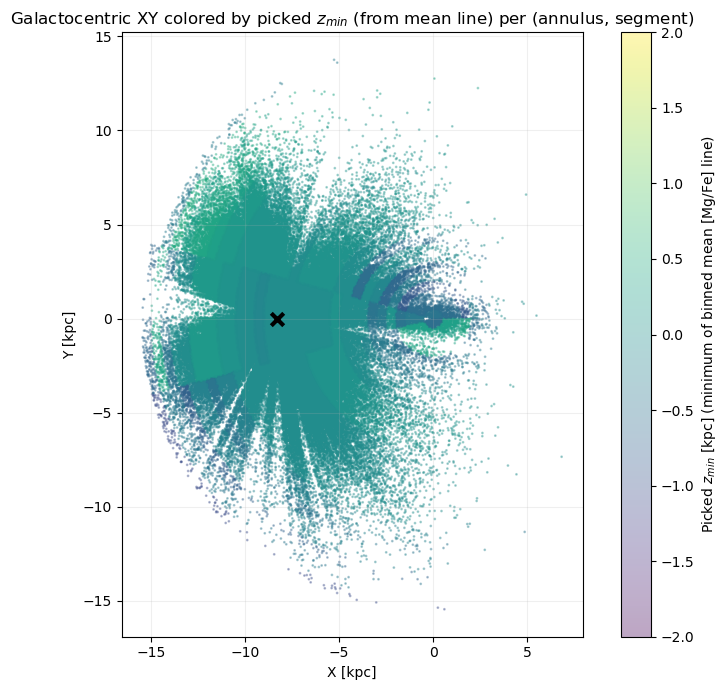

In [123]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, gaussian_filter1d
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord, Distance

# ============================================================
# USER: choose your final sample here
# ============================================================
t_final = t_poly   # <-- change to t_triangle / t_sel / t_poly as needed

# ============================================================
# 0) Build Galactocentric positions
# ============================================================
dist = Distance(np.asarray(t_final["r_med_photogeo"], float) * u.pc)

c = SkyCoord(
    ra=np.asarray(t_final["ra"], float) * u.deg,
    dec=np.asarray(t_final["dec"], float) * u.deg,
    distance=dist,
    pm_ra_cosdec=np.asarray(t_final["pmra"], float) * u.mas/u.yr,
    pm_dec=np.asarray(t_final["pmde"], float) * u.mas/u.yr,
    radial_velocity=np.asarray(t_final["v_rad"], float) * u.km/u.s,
)

galcen_frame = coord.Galactocentric(
    galcen_distance=8.275 * u.kpc,
    galcen_v_sun=[8, 254, 8] * u.km/u.s
)

gc = c.transform_to(galcen_frame)

X_all = gc.x.to_value(u.kpc)
Y_all = gc.y.to_value(u.kpc)
Z_all = gc.z.to_value(u.kpc)

R_all   = np.sqrt(X_all**2 + Y_all**2)
phi_all = np.arctan2(Y_all, X_all)   # [-pi, pi]

mgfe_all = (np.asarray(t_final["mg_h"], float) - np.asarray(t_final["fe_h"], float))
feh_all  = np.asarray(t_final["fe_h"], float)

# ============================================================
# 1) Define 3 fixed segments
#    Segment 1 = wedge between b1 and b2 (CCW)
# ============================================================
phi0 = np.pi
dphi_deg = 15          # <-- wedge half-angle: change 18 -> 15 here
dphi = np.deg2rad(dphi_deg)

b1 = phi0 - dphi
b2 = phi0 + dphi
b3 = phi0 + np.pi

def wrap_to_2pi(a):
    a = np.asarray(a)
    return np.mod(a, 2*np.pi)

def between_ccw(x, a, b):
    x = np.asarray(x)
    da = (b - a) % (2*np.pi)
    dx = (x - a) % (2*np.pi)
    return dx < da

def segment_masks(phi, b1, b2, b3):
    ph = wrap_to_2pi(phi)
    bb1, bb2, bb3 = wrap_to_2pi([b1, b2, b3])
    seg1 = between_ccw(ph, bb1, bb2)
    seg2 = between_ccw(ph, bb2, bb3)
    seg3 = between_ccw(ph, bb3, bb1)
    return {1: seg1, 2: seg2, 3: seg3}

# ============================================================
# 2) Annuli + panel settings
# ============================================================
dR = 0.5
Rmax_keep = 16.0          # <-- only go to 16 kpc (as you requested)

minN_annulus = 100         # annulus must have at least this many stars total
minN_seg_total = 50        # segment must have at least this many stars total to attempt minima

# Z/MgFe binning for mean lines + background image
z_edges    = np.linspace(-3.0, 3.0, 61)
mgfe_edges = np.linspace(-0.2, 0.6, 161)
z_centers  = 0.5 * (z_edges[:-1] + z_edges[1:])

# background image styling
cmap_name = "Greys"
smooth_sigma_img = (1.0, 1.0)  # (MgFe, Z) smoothing in pixel units for the image
vmin_pct, vmax_pct = 2.0, 99.7

# ============================================================
# 3) "Picked minimum from mean line" controls
# ============================================================
z_search_min, z_search_max = -2.5, 2.5   # don't consider outer |Z|
min_bin_count = 8                       # require >= this many stars in a Z-bin
edge_trim_bins = 2                       # drop this many valid bins from each edge (after masking)
smooth_sigma_line = 1.0                  # light smoothing (in bins) so spikes don't win

def binned_mean_and_counts(Zs, Ys, z_edges):
    """Return mean(Y) per Z bin, and N per bin."""
    nb = len(z_edges) - 1
    mean = np.full(nb, np.nan, float)
    cnt  = np.zeros(nb, int)

    # bin index per point
    inds = np.searchsorted(z_edges, Zs, side="right") - 1
    ok = (inds >= 0) & (inds < nb) & np.isfinite(Ys) & np.isfinite(Zs)
    inds = inds[ok]
    Ys = Ys[ok]

    # counts
    for i in range(nb):
        m = (inds == i)
        cnt[i] = int(np.sum(m))
        if cnt[i] > 0:
            mean[i] = np.nanmean(Ys[m])

    return mean, cnt

def pick_min_from_meanline(z_centers, mean, cnt,
                           zmin=z_search_min, zmax=z_search_max,
                           min_cnt=min_bin_count,
                           edge_trim=edge_trim_bins,
                           smooth_sigma=smooth_sigma_line):
    """
    Pick z where the (smoothed) binned mean is minimal,
    after masking low-count bins, restricting to [zmin,zmax], and trimming edges.
    """
    zc = np.asarray(z_centers)
    mean = np.asarray(mean, float)
    cnt = np.asarray(cnt, int)

    # mask: in Z range + enough counts + finite mean
    m = (zc >= zmin) & (zc <= zmax) & np.isfinite(mean) & (cnt >= min_cnt)
    idx = np.where(m)[0]
    if idx.size == 0:
        return np.nan, np.nan, "no_valid_bins"

    # optionally ensure we don't pick from the ragged ends:
    # trim a few bins from each edge of the *valid* set
    if idx.size > 2*edge_trim:
        idx = idx[edge_trim: -edge_trim]
    if idx.size == 0:
        return np.nan, np.nan, "trim_removed_all_bins"

    # smooth only the valid region values (simple: smooth the full array but keep mask)
    # to avoid NaNs poisoning, fill NaNs with nearest valid before smoothing
    mean_f = mean.copy()
    bad = ~np.isfinite(mean_f)
    if np.any(~bad):
        # nearest-neighbor fill for smoothing stability
        good_idx = np.where(~bad)[0]
        fill = np.interp(np.arange(len(mean_f)), good_idx, mean_f[good_idx])
        mean_f[bad] = fill[bad]
    else:
        return np.nan, np.nan, "all_nan_mean"

    mean_s = gaussian_filter1d(mean_f, sigma=smooth_sigma, mode="nearest")

    # pick min on trimmed valid indices
    j = idx[np.argmin(mean_s[idx])]
    return float(zc[j]), float(mean_s[j]), "ok"

# ============================================================
# 4) Filter finite + build annuli products
# ============================================================
finite_all = (
    np.isfinite(X_all) & np.isfinite(Y_all) & np.isfinite(Z_all) &
    np.isfinite(R_all) & np.isfinite(phi_all) & np.isfinite(mgfe_all)
)
X = X_all[finite_all]
Y = Y_all[finite_all]
Z = Z_all[finite_all]
R = R_all[finite_all]
phi = phi_all[finite_all]
mgfe = mgfe_all[finite_all]

# only keep radii up to 16 kpc
mRmax = (R < Rmax_keep)
X, Y, Z, R, phi, mgfe = X[mRmax], Y[mRmax], Z[mRmax], R[mRmax], phi[mRmax], mgfe[mRmax]

segm = segment_masks(phi, b1, b2, b3)

# define annuli edges explicitly so we can map stars -> annulus index later
R_edges = np.arange(0.0, Rmax_keep + dR, dR)
all_annuli = [(R_edges[i], R_edges[i+1]) for i in range(len(R_edges) - 1)]

annuli = []
imgs = []
mean_trends = []        # list of dicts {seg: mean_line}
counts_trends = []      # list of dicts {seg: N_per_bin}
Ns_by_segment = []      # list of dicts {seg: total N}
zmins_by_segment = []   # list of dicts {seg: zmin}
status_by_segment = []  # list of dicts {seg: status string}

for (Rmin, Rmax) in all_annuli:
    mR = (R >= Rmin) & (R < Rmax)
    Ntot = int(np.sum(mR))
    if Ntot < minN_annulus:
        continue

    # background image (all stars in annulus)
    Zr = Z[mR]
    Yr = mgfe[mR]
    good = np.isfinite(Zr) & np.isfinite(Yr)
    Zr = Zr[good]
    Yr = Yr[good]
    if len(Zr) < minN_annulus:
        continue

    H, _, _ = np.histogram2d(Zr, Yr, bins=[z_edges, mgfe_edges])  # (nz, nmgfe)
    colsum = H.sum(axis=1, keepdims=True)
    Hnorm = np.divide(H, colsum, out=np.zeros_like(H), where=(colsum > 0))
    img = gaussian_filter(Hnorm, sigma=(1.0, 1.0)).T  # transpose for pcolormesh(z_edges, mgfe_edges)

    trends = {}
    cnts = {}
    Ns = {}
    zmins = {}
    stats = {}

    for seg_id in [1, 2, 3]:
        m = mR & segm[seg_id]
        Ns[seg_id] = int(np.sum(m))

        if Ns[seg_id] < minN_seg_total:
            trends[seg_id] = np.full_like(z_centers, np.nan, float)
            cnts[seg_id]   = np.zeros_like(z_centers, int)
            zmins[seg_id]  = np.nan
            stats[seg_id]  = "too_few_stars"
            continue

        Zs = Z[m]
        Ys = mgfe[m]
        good = np.isfinite(Zs) & np.isfinite(Ys)
        Zs = Zs[good]
        Ys = Ys[good]

        mean_line, cnt_line = binned_mean_and_counts(Zs, Ys, z_edges)
        trends[seg_id] = mean_line
        cnts[seg_id] = cnt_line

        zmin, y_at_min, st = pick_min_from_meanline(z_centers, mean_line, cnt_line)
        zmins[seg_id] = zmin
        stats[seg_id] = st

    annuli.append((Rmin, Rmax))
    imgs.append(img)
    mean_trends.append(trends)
    counts_trends.append(cnts)
    Ns_by_segment.append(Ns)
    zmins_by_segment.append(zmins)
    status_by_segment.append(stats)

print(f"Kept {len(annuli)} annuli with Ntot ≥ {minN_annulus} and R < {Rmax_keep} kpc")

# shared vmin/vmax for density backgrounds
if len(imgs) > 0:
    vals = np.concatenate([im[(im > 0) & np.isfinite(im)] for im in imgs])
    if len(vals) > 0:
        vmin, vmax = np.percentile(vals, [vmin_pct, vmax_pct])
    else:
        vmin, vmax = 0.0, 1.0
else:
    vmin, vmax = 0.0, 1.0

# ============================================================
# 5) Print minima table
# ============================================================
print("\nPicked minima from binned mean line (interior only + support + trim + smooth)\n")
print("Rmin   Rmax     N1   z1     (st1)     N2   z2     (st2)     N3   z3     (st3)")
for i, (Rmin, Rmax) in enumerate(annuli):
    Ns = Ns_by_segment[i]
    zm = zmins_by_segment[i]
    st = status_by_segment[i]
    print(f"{Rmin:5.1f} {Rmax:5.1f}  "
          f"{Ns[1]:5d} {zm[1]:6.3f} ({st[1]:>14})   "
          f"{Ns[2]:5d} {zm[2]:6.3f} ({st[2]:>14})   "
          f"{Ns[3]:5d} {zm[3]:6.3f} ({st[3]:>14})")

# ============================================================
# 6) Multi-panel: [Mg/Fe] vs Z with vertical lines at picked minima
# ============================================================
n_panels = len(annuli)
ncols = 4
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 3.6 * nrows),
    sharex=True, sharey=True
)
axes = np.atleast_2d(axes)

colors = {1: "tab:red", 2: "tab:blue", 3: "tab:green"}
pcm = None

for i, ax in enumerate(axes.flat):
    if i >= n_panels:
        ax.axis("off")
        continue

    Rmin, Rmax = annuli[i]
    img = imgs[i]
    trends = mean_trends[i]
    Ns = Ns_by_segment[i]
    zm = zmins_by_segment[i]
    st = status_by_segment[i]

    pcm = ax.pcolormesh(
        z_edges, mgfe_edges, img,
        shading="auto",
        vmin=vmin, vmax=vmax,
        cmap=cmap_name
    )

    # mean lines
    for seg_id in [1, 2, 3]:
        ax.plot(z_centers, trends[seg_id], color=colors[seg_id], lw=1.3)

    # vertical lines at picked minima
    for seg_id in [1, 2, 3]:
        if np.isfinite(zm[seg_id]) and st[seg_id] == "ok":
            ax.axvline(zm[seg_id], color=colors[seg_id], ls="--", lw=1.2, alpha=0.9)

    ax.axvline(0, color="k", lw=0.8, alpha=0.7)

    ax.text(
        0.03, 0.95,
        rf"${Rmin:.1f}\leq R<{Rmax:.1f}$ kpc"
        + "\n"
        + rf"$N_1={Ns[1]},\,N_2={Ns[2]},\,N_3={Ns[3]}$",
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.set_xlim(-3, 3)
    ax.set_ylim(-0.2, 0.6)

    # if you want x labels on *each* panel:
    ax.set_xlabel("Z [kpc]")

# global labels (optional; you can remove if you label each panel)
fig.supylabel(r"[Mg/Fe]", fontsize=14)
fig.suptitle(r"[Mg/Fe] vs Z by annulus (3 segments) + picked minima (dashed)", fontsize=16, y=0.995)

fig.tight_layout(rect=[0.0, 0.0, 0.92, 0.97])
cax = fig.add_axes([0.935, 0.15, 0.02, 0.70])
cbar = fig.colorbar(pcm, cax=cax)
cbar.set_label(r"Column-normalized density (all stars in annulus)")

# legend once
axes.flat[0].plot([], [], color=colors[1], lw=2, label="Segment 1 (wedge)")
axes.flat[0].plot([], [], color=colors[2], lw=2, label="Segment 2")
axes.flat[0].plot([], [], color=colors[3], lw=2, label="Segment 3")
axes.flat[0].plot([], [], color="k", ls="--", lw=1.2, label="picked min z (dashed)")
axes.flat[0].legend(loc="upper right", fontsize=9, frameon=True)

plt.show()

# ============================================================
# 7) XY plot colored by picked zmin per (annulus, segment)
# ============================================================
# Build a lookup from annulus index -> zmins dict
# We'll map each star to an annulus bin and segment, then assign that zmin color.
# Note: annuli[] is a *subset* (only those kept). Make a dict keyed by (Rmin,Rmax).
zmin_lookup = {}
status_lookup = {}
for i, (Rmin, Rmax) in enumerate(annuli):
    for seg_id in [1,2,3]:
        zmin_lookup[(Rmin, Rmax, seg_id)] = zmins_by_segment[i][seg_id]
        status_lookup[(Rmin, Rmax, seg_id)] = status_by_segment[i][seg_id]

# For each star, find its (Rmin,Rmax) bin edges
# Compute bin index in the full [0,Rmax_keep) edges, then compute (Rmin,Rmax)
ann_idx = np.searchsorted(R_edges, R, side="right") - 1
ok_ann = (ann_idx >= 0) & (ann_idx < len(R_edges)-1)
ann_idx = ann_idx[ok_ann]

Xx = X[ok_ann]
Yy = Y[ok_ann]
Rr = R[ok_ann]
ph = phi[ok_ann]

segm_star = segment_masks(ph, b1, b2, b3)
seg_id_star = np.zeros_like(Rr, int)
seg_id_star[segm_star[1]] = 1
seg_id_star[segm_star[2]] = 2
seg_id_star[segm_star[3]] = 3

# assign zmin color
zmin_color = np.full_like(Rr, np.nan, float)

for k in range(len(Rr)):
    i = ann_idx[k]
    Rmin = float(R_edges[i])
    Rmax = float(R_edges[i+1])
    s = int(seg_id_star[k])
    key = (Rmin, Rmax, s)

    # only color if that annulus was kept and segment fit is ok
    if key in zmin_lookup and status_lookup[key] == "ok":
        zmin_color[k] = zmin_lookup[key]

# plot
plt.figure(figsize=(8, 7))
sc = plt.scatter(Xx, Yy, c=zmin_color, s=1, alpha=0.35)

plt.scatter(-8.275, 0, marker="x", s=80, c="k", linewidths=3, zorder=5)  # Sun marker if you want it

plt.gca().set_aspect("equal", "box")
plt.xlabel("X [kpc]")
plt.ylabel("Y [kpc]")
plt.title("Galactocentric XY colored by picked $z_{min}$ (from mean line) per (annulus, segment)")
plt.grid(alpha=0.2)

cb = plt.colorbar(sc)
cb.set_label("Picked $z_{min}$ [kpc] (minimum of binned mean [Mg/Fe] line)")

# ---- set colorbar limits to [-2, 2] (your question)
sc.set_clim(-2, 2)
cb.update_normal(sc)

plt.tight_layout()
plt.show()
